# Comparative Analysis of Pathfinding Algorithms on a Spatial Campus Graph

### Sabaragamuwa University — Campus Navigator Research Experiment

---

**Research Questions:**
- **RQ1 (Route distance):** How do route distances returned by Dijkstra, A*, and unweighted BFS compare on the campus graph?
- **RQ2 (Execution time):** How do the algorithms compare in repeated execution-time measurements on matched origin–destination pairs?
- **RQ3 (Path agreement):** How often do the algorithms return identical node sequences or overlapping edge sets on the sampled routes?
- **Supplementary validation:** How do application-reported distances compare descriptively with three independently measured campus journeys?

The automated benchmark and the three manually recorded journeys are analyzed separately. The physical journeys are a small descriptive case study, not a general accuracy validation.

---
## 0 — Imports & Global Configuration

In [3]:
import random
import time
import math
import warnings

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats

from build_graph import build_campus_graph

# ── Aesthetics ────────────────────────────────────────────────────────────────
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', font_scale=1.15)
plt.rcParams['figure.dpi'] = 120
PALETTE = {'Dijkstra': '#2c4a3b', 'A*': '#6b8f71', 'BFS': '#c96a4e'}
ALGO_ORDER = ['Dijkstra', 'A*', 'BFS']

RANDOM_SEED = 42
N_PAIRS     = 100   # number of random origin-destination pairs
TIMING_REPEATS = 10  # repeated timing observations per route and algorithm

print('All imports successful.')

All imports successful.


---
## 1 — Load the Campus Graph

The graph is built once at notebook startup from the `SABRA.kmz` file.
Each edge carries a `weight` equal to the Haversine great-circle distance (metres)
between its two endpoint nodes. Walkway segments are densified to one node every
**5 metres**, so a 100 m straight path contributes ~20 nodes and ~19 edges.

In [4]:
campus_graph = build_campus_graph('SABRA.kmz-2')

print(f'Nodes : {campus_graph.number_of_nodes():,}')
print(f'Edges : {campus_graph.number_of_edges():,}')
print(f'Connected components: {nx.number_connected_components(campus_graph)}')

Nodes : 1,953
Edges : 1,977
Connected components: 2


---
## 2 — Helper Functions

### 2.1 Haversine Distance and the A* Heuristic

The A* heuristic is the straight-line great-circle distance between two latitude–longitude nodes, in metres. If every edge weight is the Haversine distance between its endpoint coordinates, this heuristic is admissible and consistent by the triangle inequality. The graph-construction code and edge weights should be checked before relying on this guarantee.

### 2.2 `path_distance()`

For any returned node path, physical route distance is calculated by summing the stored edge weights along that path. Dijkstra and A* use those weights in route search. BFS is called without a weight argument and minimizes the number of edges; its reported physical distance is calculated afterward using the same stored edge weights.

In [5]:
def haversine(lat1: float, lon1: float, lat2: float, lon2: float) -> float:
    """Great-circle distance in metres between two (lat, lon) points."""
    R = 6_371_000
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dphi       = math.radians(lat2 - lat1)
    dlambda    = math.radians(lon2 - lon1)
    a = math.sin(dphi / 2) ** 2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlambda / 2) ** 2
    return 2 * R * math.atan2(math.sqrt(a), math.sqrt(1 - a))


def astar_heuristic(u: tuple, v: tuple) -> float:
    """Admissible A* heuristic: straight-line Haversine distance to the goal."""
    return haversine(u[0], u[1], v[0], v[1])


def path_distance(graph: nx.Graph, path: list) -> float:
    """Sum of Haversine edge weights along a given node path."""
    return sum(
        graph[path[i]][path[i + 1]]['weight']
        for i in range(len(path) - 1)
    )


print('Helper functions defined.')

Helper functions defined.


### Graph connectivity and edge-weight diagnostics

These checks record component sizes, missing/non-positive edge weights, and whether stored edge weights agree with endpoint Haversine distances. The last check assumes graph nodes are `(latitude, longitude)` tuples.

In [6]:
components = sorted(nx.connected_components(campus_graph), key=len, reverse=True)

component_summary = pd.DataFrame({
    "component_rank": range(1, len(components) + 1),
    "node_count": [len(c) for c in components],
    "edge_count": [campus_graph.subgraph(c).number_of_edges() for c in components],
})
print("Connected-component summary")
display(component_summary)

missing_weights = sum(
    1 for _, _, data in campus_graph.edges(data=True) if "weight" not in data
)
edge_weights = np.array([
    float(data["weight"])
    for _, _, data in campus_graph.edges(data=True)
    if "weight" in data
], dtype=float)

print(f"Total edges: {campus_graph.number_of_edges()}")
print(f"Edges missing 'weight': {missing_weights}")
if len(edge_weights):
    print(f"Minimum edge weight: {edge_weights.min():.6f} m")
    print(f"Median edge weight : {np.median(edge_weights):.6f} m")
    print(f"Maximum edge weight: {edge_weights.max():.6f} m")
    print(f"Non-positive weights: {(edge_weights <= 0).sum()}")

weight_errors = []
for u, v, data in campus_graph.edges(data=True):
    if "weight" not in data:
        continue
    expected = haversine(u[0], u[1], v[0], v[1])
    weight_errors.append(abs(float(data["weight"]) - expected))

if weight_errors:
    print(
        "Maximum absolute difference between stored edge weight and "
        f"endpoint Haversine distance: {max(weight_errors):.8f} m"
    )

Connected-component summary


,component_rank,node_count,edge_count
0,1,1947,1972
1,2,6,5


Total edges: 1977
Edges missing 'weight': 0
Minimum edge weight: 1.199789 m
Median edge weight : 5.175305 m
Maximum edge weight: 9.846096 m
Non-positive weights: 0
Maximum absolute difference between stored edge weight and endpoint Haversine distance: 0.00000000 m


In [26]:
G = campus_graph
n_cycles = G.number_of_edges() - G.number_of_nodes() + nx.number_connected_components(G)
bridge_set = {frozenset(e) for e in nx.bridges(G)}

def touches_cycle(path):
    return any(frozenset((path[i], path[i+1])) not in bridge_set
               for i in range(len(path)-1))

d = df[df.algorithm == "Dijkstra"].set_index("route_id")
d["touches_cycle"] = d["path_nodes"].apply(touches_cycle)
bfs_longer_ids = bfs_overhead_m[bfs_overhead_m > 1e-8].index
print(n_cycles, d["touches_cycle"].sum(), d.loc[bfs_longer_ids, "touches_cycle"].all())

26 98 True


In [25]:
import heapq
from collections import deque

def _rebuild(parent, t):
    path = []
    while t is not None:
        path.append(t); t = parent[t]
    return path[::-1]

def dijkstra_counted(G, s, t):
    dist, parent, done = {s: 0.0}, {s: None}, set()
    pq, expanded = [(0.0, s)], 0
    while pq:
        d, u = heapq.heappop(pq)
        if u in done: continue
        done.add(u); expanded += 1
        if u == t: break
        for v, data in G[u].items():
            nd = d + data["weight"]
            if nd < dist.get(v, float("inf")):
                dist[v], parent[v] = nd, u
                heapq.heappush(pq, (nd, v))
    return _rebuild(parent, t), expanded

def astar_counted(G, s, t):
    g, parent, done = {s: 0.0}, {s: None}, set()
    pq, expanded = [(astar_heuristic(s, t), s)], 0
    while pq:
        _, u = heapq.heappop(pq)
        if u in done: continue
        done.add(u); expanded += 1
        if u == t: break
        for v, data in G[u].items():
            ng = g[u] + data["weight"]
            if ng < g.get(v, float("inf")):
                g[v], parent[v] = ng, u
                heapq.heappush(pq, (ng + astar_heuristic(v, t), v))
    return _rebuild(parent, t), expanded

def bfs_counted(G, s, t):
    parent, q, expanded = {s: None}, deque([s]), 0
    while q:
        u = q.popleft(); expanded += 1
        if u == t: break
        for v in G[u]:
            if v not in parent:
                parent[v] = u; q.append(v)
    return _rebuild(parent, t), expanded

---
## 3 — Automated Testing Function

### Methodology

The experiment samples 100 connected origin–destination pairs using a fixed random seed. Each pair is evaluated using Dijkstra's algorithm, A* search, and unweighted breadth-first search (BFS).

For each route, the implementation records the endpoints, returned node sequence, path distance, number of nodes, and execution time. Edge weights represent Haversine distances in metres. Dijkstra and A* use these weights to minimize total route distance; BFS ignores the weights and minimizes the number of edges.

Each algorithm is first executed as a warm-up, after which it is timed repeatedly. The algorithm execution order is randomized across repetitions to reduce systematic timing-order effects. The median measured execution time is retained for each route–algorithm combination.

Because all algorithms are evaluated on the same endpoints, route-level performance comparisons are paired. The repeated timing procedure reduces dependence on a single timing observation, although very short execution times remain sensitive to system load, interpreter overhead, and hardware.

The fixed seed, graph input, graph-construction code, and software versions should be recorded for reproducibility.

In [7]:
def automated_testing(
    graph: nx.Graph,
    n_pairs: int = 100,
    seed: int = 42,
    timing_repeats: int = 10,
    max_attempts_factor: int = 100,
) -> pd.DataFrame:
    """
    Benchmark Dijkstra, A*, and unweighted BFS on matched connected pairs.

    One row is returned per route and algorithm. execution_time_ms is the
    median of repeated timed calls. Actual paths and endpoints are retained
    for paired analysis and route-sequence comparison.
    """
    rng = random.Random(seed)
    nodes = list(graph.nodes())

    if len(nodes) < 2:
        raise ValueError("The graph must contain at least two nodes.")
    if timing_repeats < 1:
        raise ValueError("timing_repeats must be at least 1.")

    def run_algorithm(algo, start, end):
        if algo == "Dijkstra":
            return nx.shortest_path(
                graph, source=start, target=end, weight="weight",
                method="dijkstra"
            )
        if algo == "A*":
            return nx.astar_path(
                graph, source=start, target=end,
                heuristic=astar_heuristic, weight="weight"
            )
        if algo == "BFS":
            # No weight argument: BFS minimizes edge count (hops).
            return nx.shortest_path(graph, source=start, target=end)
        raise ValueError(f"Unknown algorithm: {algo}")

    algorithms = ["Dijkstra", "A*", "BFS"]
    records = []
    route_id = 0
    attempts = 0
    max_attempts = n_pairs * max_attempts_factor

    while route_id < n_pairs and attempts < max_attempts:
        attempts += 1
        start, end = rng.sample(nodes, 2)

        # Reject disconnected pairs so every algorithm uses identical endpoints.
        try:
            paths = {
                algo: run_algorithm(algo, start, end)
                for algo in algorithms
            }
        except nx.NetworkXNoPath:
            continue

        # Warm-up calls are excluded from measured timings.
        warm_order = algorithms.copy()
        rng.shuffle(warm_order)
        for algo in warm_order:
            run_algorithm(algo, start, end)

        timings = {algo: [] for algo in algorithms}

        # Randomize algorithm order on every repetition.
        for _ in range(timing_repeats):
            order = algorithms.copy()
            rng.shuffle(order)
            for algo in order:
                t0 = time.perf_counter_ns()
                run_algorithm(algo, start, end)
                t1 = time.perf_counter_ns()
                timings[algo].append((t1 - t0) / 1_000_000)

        for algo in algorithms:
            path = paths[algo]
            records.append({
                "route_id": route_id,
                "start_node": start,
                "end_node": end,
                "algorithm": algo,
                "execution_time_ms": float(np.median(timings[algo])),
                "timing_repeats": timing_repeats,
                "distance": path_distance(graph, path),
                "node_count": len(path),
                "path_nodes": path,
            })

        route_id += 1
        if route_id % 10 == 0:
            print(f"  Completed {route_id}/{n_pairs} pairs...")

    if route_id < n_pairs:
        raise RuntimeError(
            f"Only {route_id}/{n_pairs} connected pairs found after "
            f"{attempts} attempts. Check graph connectivity or increase "
            "max_attempts_factor."
        )

    df_out = pd.DataFrame(records)
    df_out["algorithm"] = pd.Categorical(
        df_out["algorithm"], categories=["Dijkstra", "A*", "BFS"],
        ordered=True
    )

    print(f"\nDone. {route_id} matched routes in {attempts} sampling attempts.")
    print(f"Timing observations per route–algorithm combination: {timing_repeats}")
    print("Reported execution time is the median repeated timing (ms).")
    return df_out


print("Repeated matched benchmark function defined.")

Repeated matched benchmark function defined.


---
## 4 — Run the Experiment

The benchmark evaluates 100 connected origin–destination pairs with all three algorithms. Each route–algorithm combination is timed repeatedly; the median is retained as its execution-time value. This produces 300 route–algorithm rows, with repeated timing observations summarized within each row.

In [8]:
print(
    f"Running {N_PAIRS} matched test pairs "
    f"(seed={RANDOM_SEED}, timing repeats={TIMING_REPEATS})...\n"
)
df = automated_testing(
    campus_graph,
    n_pairs=N_PAIRS,
    seed=RANDOM_SEED,
    timing_repeats=TIMING_REPEATS,
)

# Quick sanity check
display(df.drop(columns=["path_nodes"]).head(9))

Running 100 matched test pairs (seed=42, timing repeats=10)...

  Completed 10/100 pairs...
  Completed 20/100 pairs...
  Completed 30/100 pairs...
  Completed 40/100 pairs...
  Completed 50/100 pairs...
  Completed 60/100 pairs...
  Completed 70/100 pairs...
  Completed 80/100 pairs...
  Completed 90/100 pairs...
  Completed 100/100 pairs...

Done. 100 matched routes in 100 sampling attempts.
Timing observations per route–algorithm combination: 10
Reported execution time is the median repeated timing (ms).


,route_id,start_node,end_node,algorithm,execution_time_ms,timing_repeats,distance,node_count
0,0,"(6.708914541666666, 80.791478925)","(6.7148278625, 80.78885445)",Dijkstra,1.889125,10,925.268402,173
1,0,"(6.708914541666666, 80.791478925)","(6.7148278625, 80.78885445)",A*,0.696729,10,925.268402,173
2,0,"(6.708914541666666, 80.791478925)","(6.7148278625, 80.78885445)",BFS,0.528895,10,925.268402,173
3,1,"(6.706398718181818, 80.78721065454546)","(6.711697557142857, 80.78902501428571)",Dijkstra,0.730500,10,1316.385653,255
4,1,"(6.706398718181818, 80.78721065454546)","(6.711697557142857, 80.78902501428571)",A*,0.551479,10,1316.385653,255
5,1,"(6.706398718181818, 80.78721065454546)","(6.711697557142857, 80.78902501428571)",BFS,0.252125,10,1316.385653,255
6,2,"(6.70565114, 80.78888632)","(6.711341913043478, 80.7876924347826)",Dijkstra,0.513354,10,750.716439,148
7,2,"(6.70565114, 80.78888632)","(6.711341913043478, 80.7876924347826)",A*,0.269875,10,750.716439,148
8,2,"(6.70565114, 80.78888632)","(6.711341913043478, 80.7876924347826)",BFS,0.180250,10,750.716439,148


In [22]:
# ── Descriptive statistics per algorithm ─────────────────────────────────────
summary = (
    df.groupby('algorithm', observed=True)[['execution_time_ms', 'distance', 'node_count']]
    .agg(['mean', 'median', 'std', 'min', 'max'])
    .round(4)
)
print('=== Summary Statistics ===')
display(summary)

=== Summary Statistics ===


execution_time_ms                                  distance  \
                       mean  median     std     min     max      mean   
algorithm                                                               
Dijkstra             1.0918  0.8340  0.7990  0.0158  3.0438  896.1553   
A*                   0.7850  0.5732  0.7039  0.0111  3.0195  896.1553   
BFS                  0.3499  0.3081  0.2311  0.0065  0.8150  897.6583   

                                                  node_count                   \
             median       std      min        max       mean median       std   
algorithm                                                                       
Dijkstra   780.4603  596.6852  25.5766  2593.8057     171.40  148.5  114.9667   
A*         780.4603  596.6852  25.5766  2593.8057     171.40  148.5  114.9667   
BFS        782.9187  597.8914  25.5766  2593.8057     171.22  148.0  114.8414   

                    
          min  max  
algorithm           
Dijkstra    6  495  
A*          6  495  
BFS         6  495

---
## 5 — RQ1: Accuracy — Do All Algorithms Produce Equally Short Physical Routes?

**Hypothesis:** Dijkstra and A\* should return *identical* physical distances (both optimise for
minimum Haversine weight). BFS, which counts only hops across the densified 5 m grid,
is expected to return routes that are measurably *longer* in metres.

The bar chart shows **mean physical distance ± 95 % CI** for all three algorithms across the 100 test routes.

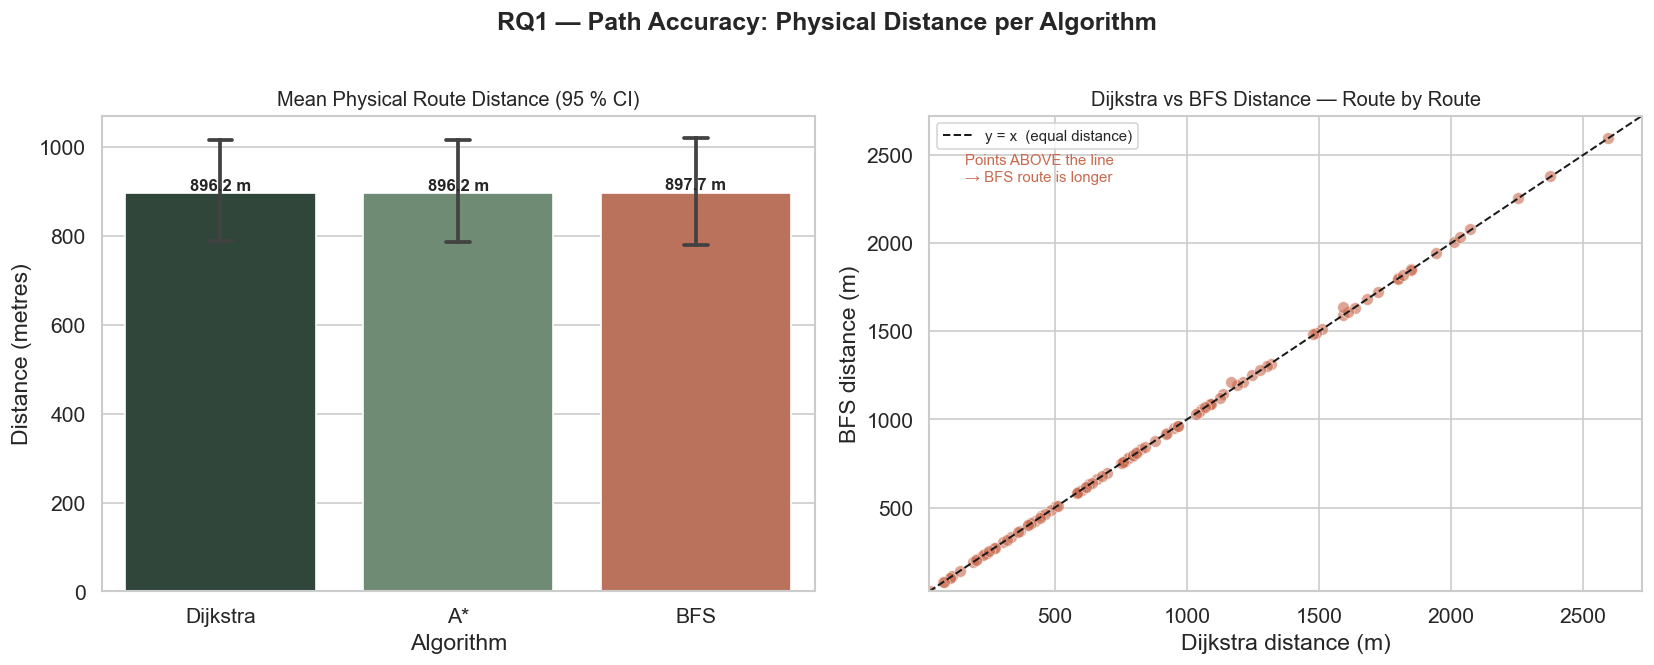

Saved → rq1_accuracy.png


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
fig.suptitle('RQ1 — Path Accuracy: Physical Distance per Algorithm', fontsize=15, fontweight='bold', y=1.01)

# ── Left: mean bar chart with 95 % CI ────────────────────────────────────────
ax1 = axes[0]
sns.barplot(
    data=df, x='algorithm', y='distance',
    palette=PALETTE, errorbar=('ci', 95),
    order=ALGO_ORDER, ax=ax1, capsize=0.1
)
ax1.set_title('Mean Physical Route Distance (95 % CI)', fontsize=12)
ax1.set_xlabel('Algorithm')
ax1.set_ylabel('Distance (metres)')

# Annotate bar tops with mean values
for bar, algo in zip(ax1.patches, ALGO_ORDER):
    mean_val = df[df['algorithm'] == algo]['distance'].mean()
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f'{mean_val:.1f} m',
        ha='center', va='bottom', fontsize=10, fontweight='bold'
    )

# ── Right: scatter — Dijkstra vs BFS distances, route by route ───────────────
ax2 = axes[1]
dijk_dist = df[df['algorithm'] == 'Dijkstra'].set_index('route_id')['distance']
bfs_dist  = df[df['algorithm'] == 'BFS'].set_index('route_id')['distance']
common    = dijk_dist.index.intersection(bfs_dist.index)

ax2.scatter(dijk_dist[common], bfs_dist[common],
            alpha=0.6, s=50, color=PALETTE['BFS'], edgecolors='white', linewidth=0.5)

# y = x reference line (equal accuracy)
lim_max = max(dijk_dist[common].max(), bfs_dist[common].max()) * 1.05
lim_min = min(dijk_dist[common].min(), bfs_dist[common].min()) * 0.95
ax2.plot([lim_min, lim_max], [lim_min, lim_max],
         'k--', linewidth=1.2, label='y = x  (equal distance)')

ax2.set_title('Dijkstra vs BFS Distance — Route by Route', fontsize=12)
ax2.set_xlabel('Dijkstra distance (m)')
ax2.set_ylabel('BFS distance (m)')
ax2.legend(fontsize=9)
ax2.set_xlim(lim_min, lim_max)
ax2.set_ylim(lim_min, lim_max)

ax2.text(0.05, 0.92, 'Points ABOVE the line\n→ BFS route is longer',
         transform=ax2.transAxes, fontsize=9, color=PALETTE['BFS'],
         verticalalignment='top')

plt.tight_layout()
plt.savefig('rq1_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → rq1_accuracy.png')

In [24]:
# Route-level weighted-distance comparisons (matched route IDs).
wide_distance = df.pivot(index="route_id", columns="algorithm", values="distance")
d_a_diff = wide_distance["Dijkstra"] - wide_distance["A*"]
d_a_abs = d_a_diff.abs()
tol_m = 1e-8

print("=== Dijkstra vs A* route distance ===")
print(f"Routes evaluated: {len(d_a_diff)}")
print(f"Maximum absolute difference: {d_a_abs.max():.10f} m")
print(f"Mean absolute difference: {d_a_abs.mean():.10f} m")
print(f"Equal within {tol_m:g} m: {np.isclose(d_a_diff, 0, atol=tol_m, rtol=0).sum()} / {len(d_a_diff)}")

bfs_overhead_m = wide_distance["BFS"] - wide_distance["Dijkstra"]
bfs_overhead_pct = 100 * bfs_overhead_m / wide_distance["Dijkstra"]

print("\n=== BFS vs Dijkstra weighted distance ===")
print(f"BFS longer: {(bfs_overhead_m > tol_m).sum()} / {len(bfs_overhead_m)}")
print(f"Equal within tolerance: {np.isclose(bfs_overhead_m, 0, atol=tol_m, rtol=0).sum()} / {len(bfs_overhead_m)}")
print(f"BFS shorter: {(bfs_overhead_m < -tol_m).sum()} / {len(bfs_overhead_m)}")
print(f"Mean extra distance: {bfs_overhead_m.mean():.4f} m")
print(f"Median extra distance: {bfs_overhead_m.median():.4f} m")
print(f"Mean percentage overhead: {bfs_overhead_pct.mean():.4f}%")
print(f"Median percentage overhead: {bfs_overhead_pct.median():.4f}%")
print(f"Maximum percentage overhead: {bfs_overhead_pct.max():.4f}%")


=== Dijkstra vs A* route distance ===
Routes evaluated: 100
Maximum absolute difference: 0.0000000000 m
Mean absolute difference: 0.0000000000 m
Equal within 1e-08 m: 100 / 100

=== BFS vs Dijkstra weighted distance ===
BFS longer: 14 / 100
Equal within tolerance: 86 / 100
BFS shorter: 0 / 100
Mean extra distance: 1.5030 m
Median extra distance: 0.0000 m
Mean percentage overhead: 0.1234%
Median percentage overhead: 0.0000%
Maximum percentage overhead: 3.9740%


---
## 6 — RQ2: Computational Speed — How Do the Algorithms Compare?

The box plot shows the execution-time distributions across matched routes. Each route–algorithm timing is the median of repeated calls, with randomized algorithm order and a warm-up call.

A* may benefit from the destination-directed heuristic, but an observed lower mean does not by itself establish a statistically reliable advantage. The paired comparisons below quantify within-route differences and report confidence intervals and adjusted p-values. Conclusions apply to this graph, implementation, and timing environment.

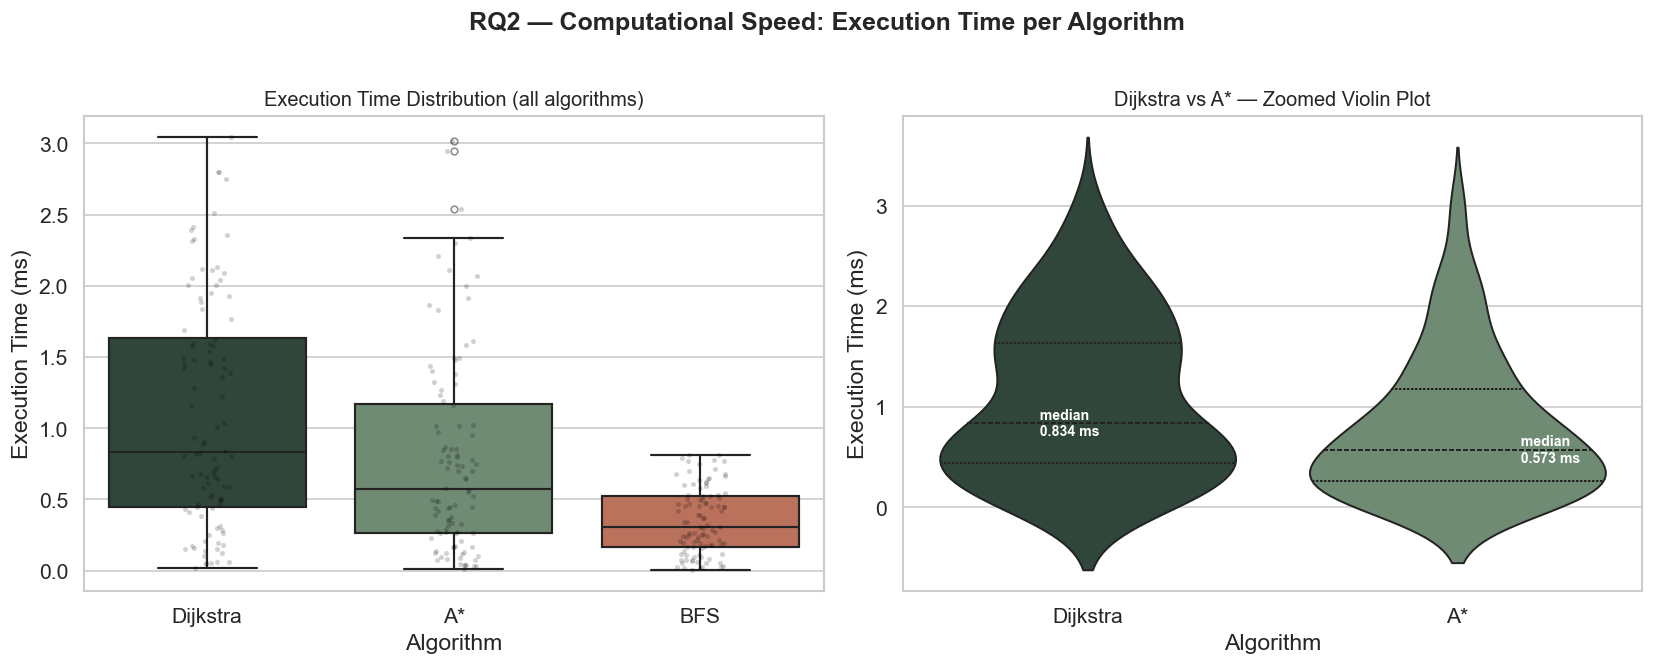

Saved → rq2_speed.png


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
fig.suptitle('RQ2 — Computational Speed: Execution Time per Algorithm', fontsize=15, fontweight='bold', y=1.01)

# ── Left: box plot — all three algorithms ────────────────────────────────────
ax1 = axes[0]
sns.boxplot(
    data=df, x='algorithm', y='execution_time_ms',
    palette=PALETTE, order=ALGO_ORDER,
    linewidth=1.3, flierprops=dict(marker='o', markersize=4, alpha=0.5),
    ax=ax1
)
sns.stripplot(
    data=df, x='algorithm', y='execution_time_ms',
    order=ALGO_ORDER,
    color='black', alpha=0.18, size=3, jitter=True, ax=ax1
)
ax1.set_title('Execution Time Distribution (all algorithms)', fontsize=12)
ax1.set_xlabel('Algorithm')
ax1.set_ylabel('Execution Time (ms)')

# ── Right: zoomed Dijkstra vs A* violin plot ──────────────────────────────────
ax2 = axes[1]
df_da = df[df['algorithm'].isin(['Dijkstra', 'A*'])].copy()
sns.violinplot(
    data=df_da, x='algorithm', y='execution_time_ms',
    palette={'Dijkstra': PALETTE['Dijkstra'], 'A*': PALETTE['A*']},
    order=['Dijkstra', 'A*'], inner='quartile', linewidth=1.2, ax=ax2
)
ax2.set_title('Dijkstra vs A* — Zoomed Violin Plot', fontsize=12)
ax2.set_xlabel('Algorithm')
ax2.set_ylabel('Execution Time (ms)')

# Annotate medians
for algo, offset in [('Dijkstra', -0.15), ('A*', 0.15)]:
    med = df_da[df_da['algorithm'] == algo]['execution_time_ms'].median()
    ax2.text(offset + (['Dijkstra', 'A*'].index(algo)), med,
             f'  median\n  {med:.3f} ms', fontsize=8.5,
             color='white', fontweight='bold', va='center')

plt.tight_layout()
plt.savefig('rq2_speed.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → rq2_speed.png')

In [13]:
# Paired statistical comparisons using matched route IDs.
# Positive difference means the first-listed algorithm has a larger metric.

from itertools import combinations


def paired_bootstrap_ci(values, confidence=0.95, n_boot=10000, seed=42):
    """Percentile bootstrap confidence interval for the mean paired difference."""
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) == 0:
        return np.nan, np.nan

    rng = np.random.default_rng(seed)
    boot_means = np.empty(n_boot)
    for i in range(n_boot):
        sample = rng.choice(values, size=len(values), replace=True)
        boot_means[i] = sample.mean()

    alpha = 1 - confidence
    lo, hi = np.quantile(boot_means, [alpha / 2, 1 - alpha / 2])
    return float(lo), float(hi)


def holm_adjust(p_values):
    """Holm family-wise error correction; returns adjusted p-values."""
    p_values = np.asarray(p_values, dtype=float)
    m = len(p_values)
    order = np.argsort(p_values)
    adjusted = np.empty(m)
    running_max = 0.0

    for rank, idx in enumerate(order):
        running_max = max(running_max, (m - rank) * p_values[idx])
        adjusted[idx] = min(running_max, 1.0)
    return adjusted


def paired_comparison_table(data, metric, comparisons, seed=42):
    wide = data.pivot(index="route_id", columns="algorithm", values=metric)
    rows = []

    for first, second in comparisons:
        pair = wide[[first, second]].dropna()
        differences = pair[first].to_numpy() - pair[second].to_numpy()

        mean_diff = float(np.mean(differences))
        median_diff = float(np.median(differences))
        ci_low, ci_high = paired_bootstrap_ci(differences, seed=seed)

        if np.allclose(differences, 0):
            t_stat, t_p = 0.0, 1.0
            w_stat, w_p = 0.0, 1.0
        else:
            t_result = stats.ttest_rel(pair[first], pair[second])
            t_stat, t_p = float(t_result.statistic), float(t_result.pvalue)
            try:
                w_result = stats.wilcoxon(
                    pair[first], pair[second],
                    alternative="two-sided", zero_method="wilcox"
                )
                w_stat, w_p = float(w_result.statistic), float(w_result.pvalue)
            except ValueError:
                w_stat, w_p = np.nan, np.nan

        rows.append({
            "metric": metric,
            "comparison": f"{first} − {second}",
            "n_pairs": len(differences),
            "mean_difference": mean_diff,
            "median_difference": median_diff,
            "mean_diff_CI95_low": ci_low,
            "mean_diff_CI95_high": ci_high,
            "paired_t": t_stat,
            "paired_t_p": t_p,
            "wilcoxon_W": w_stat,
            "wilcoxon_p": w_p,
            "first_larger_count": int((differences > 0).sum()),
            "second_larger_count": int((differences < 0).sum()),
            "ties": int(np.isclose(differences, 0).sum()),
        })

    out = pd.DataFrame(rows)
    out["wilcoxon_p_holm"] = holm_adjust(
        out["wilcoxon_p"].fillna(1.0).to_numpy()
    )
    return out


comparisons = [("A*", "Dijkstra"), ("BFS", "Dijkstra"), ("BFS", "A*")]

time_tests = paired_comparison_table(
    df, "execution_time_ms", comparisons, seed=RANDOM_SEED
)
distance_tests = paired_comparison_table(
    df, "distance", comparisons, seed=RANDOM_SEED
)

print("PAIRED EXECUTION-TIME COMPARISONS (ms)")
display(time_tests.round(6))

print("PAIRED ROUTE-DISTANCE COMPARISONS (m)")
display(distance_tests.round(6))

time_summary = (
    df.groupby("algorithm", observed=True)["execution_time_ms"]
      .agg(["count", "mean", "median", "std", "min", "max"])
      .round(6)
)
print("Execution-time summary (ms)")
display(time_summary)

distance_summary = (
    df.groupby("algorithm", observed=True)["distance"]
      .agg(["count", "mean", "median", "std", "min", "max"])
      .round(4)
)
print("Route-distance summary (m)")
display(distance_summary)

PAIRED EXECUTION-TIME COMPARISONS (ms)


,metric,comparison,n_pairs,mean_difference,median_difference,mean_diff_CI95_low,mean_diff_CI95_high,paired_t,paired_t_p,wilcoxon_W,wilcoxon_p,first_larger_count,second_larger_count,ties,wilcoxon_p_holm
0,execution_time_ms,A* − Dijkstra,100,-0.306808,-0.218813,-0.405799,-0.202354,-5.916755,0.0,654.0,0.0,13,87,0,0.0
1,execution_time_ms,BFS − Dijkstra,100,-0.741902,-0.546896,-0.857850,-0.633007,-12.956705,0.0,0.0,0.0,0,100,0,0.0
2,execution_time_ms,BFS − A*,100,-0.435094,-0.252094,-0.546179,-0.335653,-8.023209,0.0,104.0,0.0,5,95,0,0.0


PAIRED ROUTE-DISTANCE COMPARISONS (m)


,metric,comparison,n_pairs,mean_difference,median_difference,mean_diff_CI95_low,mean_diff_CI95_high,paired_t,paired_t_p,wilcoxon_W,wilcoxon_p,first_larger_count,second_larger_count,ties,wilcoxon_p_holm
0,distance,A* − Dijkstra,100,0.000000,0.0,0.000000,0.000000,0.000000,1.000000,0.0,1.000000,0,0,100,1.000000
1,distance,BFS − Dijkstra,100,1.503003,0.0,0.441978,2.959081,2.258516,0.026108,0.0,0.000976,14,0,86,0.002928
2,distance,BFS − A*,100,1.503003,0.0,0.441978,2.959081,2.258516,0.026108,0.0,0.000976,14,0,86,0.002928


Execution-time summary (ms)


,count,mean,median,std,min,max
algorithm,,,,,,
Dijkstra,100,1.091779,0.833968,0.798999,0.015812,3.043834
A*,100,0.784971,0.573219,0.703878,0.011062,3.019458
BFS,100,0.349877,0.308104,0.231131,0.006458,0.815021


Route-distance summary (m)


,count,mean,median,std,min,max
algorithm,,,,,,
Dijkstra,100,896.1553,780.4603,596.6852,25.5766,2593.8057
A*,100,896.1553,780.4603,596.6852,25.5766,2593.8057
BFS,100,897.6583,782.9187,597.8914,25.5766,2593.8057


### How to report the paired tests

For each comparison, report the mean paired difference and 95% bootstrap confidence interval, then give the paired t-test and Holm-adjusted Wilcoxon p-value. The sign follows the table's comparison order: a negative A* − Dijkstra timing difference means A* was faster on average. Do not describe a difference as statistically significant unless the reported p-value supports that statement. These tests compare the sampled routes on this graph and do not establish universal algorithm performance.

---
## 7 — RQ3: Compare Returned Paths Across All Routes

This section compares the actual node sequences and undirected edge sets for every sampled origin–destination pair. Exact sequence equality is reported separately from edge-set equality and Jaccard similarity. A single route map remains a qualitative illustration, while the full route-level comparison supports conclusions about path agreement.

Dijkstra and A* optimize the same weighted objective, but equal route distances do not necessarily imply identical node sequences when multiple optimal paths exist. BFS minimizes edge count rather than total edge weight, so its path can differ from the weighted shortest path.

In [14]:
# Use the actual paths retained from the benchmark, rather than rerunning a separate sample.
route0 = df[df["route_id"] == 0].set_index("algorithm")
start_node = route0.loc["Dijkstra", "start_node"]
end_node = route0.loc["Dijkstra", "end_node"]
path_dijkstra = route0.loc["Dijkstra", "path_nodes"]
path_astar = route0.loc["A*", "path_nodes"]
path_bfs = route0.loc["BFS", "path_nodes"]

print(f"Route ID: 0")
print(f"Start: {start_node}")
print(f"End:   {end_node}")
print(f"Dijkstra nodes: {len(path_dijkstra)}")
print(f"A* nodes:       {len(path_astar)}")
print(f"BFS nodes:      {len(path_bfs)}")

Route ID: 0
Start: (6.708914541666666, 80.791478925)
End:   (6.7148278625, 80.78885445)
Dijkstra nodes: 173
A* nodes:       173
BFS nodes:      173


### Quantitative path-sequence comparison

Exact node-sequence equality, undirected edge-set equality, and edge-set Jaccard similarity are computed for every route. Jaccard similarity is descriptive: a value of 1 means the paths use the same undirected edge set, but does not necessarily mean their ordered node sequences are identical.

In [15]:
def path_edge_set(path):
    """Represent a path as a set of undirected edges."""
    return {
        frozenset((path[i], path[i + 1]))
        for i in range(len(path) - 1)
    }


def edge_jaccard(edges_1, edges_2):
    union = edges_1 | edges_2
    return len(edges_1 & edges_2) / len(union) if union else 1.0


path_rows = []
for route_id, route_df in df.groupby("route_id", sort=True):
    paths = {
        row["algorithm"]: row["path_nodes"]
        for _, row in route_df.iterrows()
    }

    d_path, a_path, b_path = paths["Dijkstra"], paths["A*"], paths["BFS"]
    d_edges, a_edges, b_edges = (
        path_edge_set(d_path), path_edge_set(a_path), path_edge_set(b_path)
    )

    path_rows.append({
        "route_id": route_id,
        "dijkstra_astar_identical_sequence": d_path == a_path,
        "dijkstra_astar_same_edges": d_edges == a_edges,
        "dijkstra_astar_edge_jaccard": edge_jaccard(d_edges, a_edges),
        "dijkstra_bfs_identical_sequence": d_path == b_path,
        "dijkstra_bfs_edge_jaccard": edge_jaccard(d_edges, b_edges),
        "astar_bfs_identical_sequence": a_path == b_path,
        "astar_bfs_edge_jaccard": edge_jaccard(a_edges, b_edges),
        "dijkstra_distance_m": path_distance(campus_graph, d_path),
        "astar_distance_m": path_distance(campus_graph, a_path),
        "bfs_distance_m": path_distance(campus_graph, b_path),
        "dijkstra_nodes": len(d_path),
        "astar_nodes": len(a_path),
        "bfs_nodes": len(b_path),
        "dijkstra_bfs_same_edges": d_edges == b_edges,
        "astar_bfs_same_edges": a_edges == b_edges,
    })

path_comparison = pd.DataFrame(path_rows)

summary_path = pd.DataFrame([
    {
        "comparison": "Dijkstra vs A*",
        "identical_sequences": int(path_comparison["dijkstra_astar_identical_sequence"].sum()),
        "identical_sequence_pct": 100 * path_comparison["dijkstra_astar_identical_sequence"].mean(),
        "same_edge_sets": int(path_comparison["dijkstra_astar_same_edges"].sum()),
        "mean_edge_jaccard": path_comparison["dijkstra_astar_edge_jaccard"].mean(),
    },
    {
        "comparison": "Dijkstra vs BFS",
        "identical_sequences": int(path_comparison["dijkstra_bfs_identical_sequence"].sum()),
        "identical_sequence_pct": 100 * path_comparison["dijkstra_bfs_identical_sequence"].mean(),
        "same_edge_sets": np.nan,
        "mean_edge_jaccard": path_comparison["dijkstra_bfs_edge_jaccard"].mean(),
    },
    {
        "comparison": "A* vs BFS",
        "identical_sequences": int(path_comparison["astar_bfs_identical_sequence"].sum()),
        "identical_sequence_pct": 100 * path_comparison["astar_bfs_identical_sequence"].mean(),
        "same_edge_sets": np.nan,
        "mean_edge_jaccard": path_comparison["astar_bfs_edge_jaccard"].mean(),
    },
])

print("Path agreement summary across all sampled routes")
display(summary_path.round(4))

d_a_dist_equal = np.isclose(
    path_comparison["dijkstra_distance_m"],
    path_comparison["astar_distance_m"],
    rtol=0, atol=1e-8
)
print(
    f"Dijkstra/A* equal-distance routes: "
    f"{d_a_dist_equal.sum()} / {len(path_comparison)}"
)

bfs_longer = (
    path_comparison["bfs_distance_m"]
    > path_comparison["dijkstra_distance_m"] + 1e-8
)
print(
    f"BFS routes longer in weighted distance than Dijkstra: "
    f"{bfs_longer.sum()} / {len(path_comparison)}"
)

Path agreement summary across all sampled routes


,comparison,identical_sequences,identical_sequence_pct,same_edge_sets,mean_edge_jaccard
0,Dijkstra vs A*,100,100.0,100.0,1.0000
1,Dijkstra vs BFS,86,86.0,NaN,0.9153
2,A* vs BFS,86,86.0,NaN,0.9153


Dijkstra/A* equal-distance routes: 100 / 100
BFS routes longer in weighted distance than Dijkstra: 14 / 100


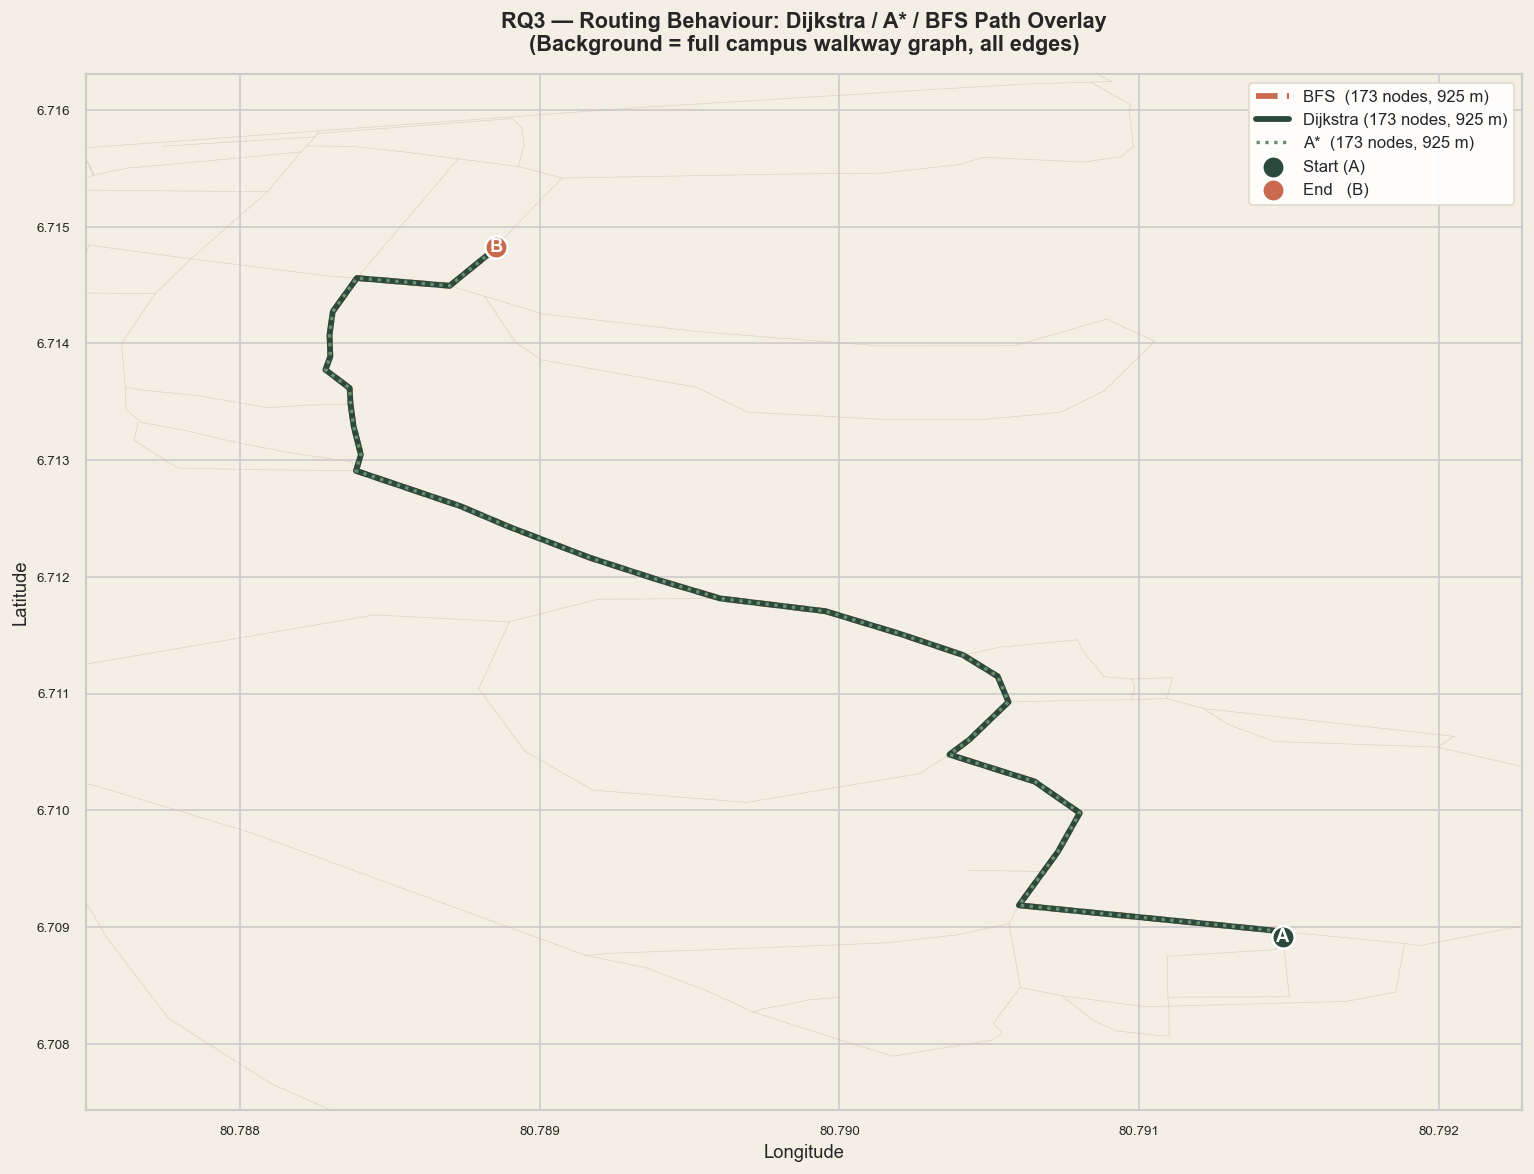

Saved → rq3_behaviour.png


In [16]:
fig, ax = plt.subplots(figsize=(13, 10))
fig.patch.set_facecolor('#f4efe4')
ax.set_facecolor('#f4efe4')

# ── 1. Draw the full graph skeleton in the background ────────────────────────
for u, v in campus_graph.edges():
    ax.plot([u[1], v[1]], [u[0], v[0]],
            color='#c8c1b0', linewidth=0.4, alpha=0.6, zorder=1)

# ── 2. Helper to draw a path ─────────────────────────────────────────────────
def draw_path(ax, path, color, lw, label, zorder, linestyle='-'):
    lons = [n[1] for n in path]
    lats = [n[0] for n in path]
    ax.plot(lons, lats, color=color, linewidth=lw,
            linestyle=linestyle, label=label, zorder=zorder,
            solid_capstyle='round', solid_joinstyle='round')

# BFS drawn first so Dijkstra/A* render on top
draw_path(ax, path_bfs,      color=PALETTE['BFS'],      lw=3.5, label=f'BFS  ({len(path_bfs)} nodes, {path_distance(campus_graph, path_bfs):.0f} m)',      zorder=3, linestyle='--')
draw_path(ax, path_dijkstra, color=PALETTE['Dijkstra'], lw=3.5, label=f'Dijkstra ({len(path_dijkstra)} nodes, {path_distance(campus_graph, path_dijkstra):.0f} m)', zorder=4)
draw_path(ax, path_astar,    color=PALETTE['A*'],       lw=2.0, label=f'A*  ({len(path_astar)} nodes, {path_distance(campus_graph, path_astar):.0f} m)',       zorder=5, linestyle=':')

# ── 3. Mark start and end ────────────────────────────────────────────────────
ax.scatter(start_node[1], start_node[0], s=180, color='#2c4a3b',
           zorder=6, edgecolors='white', linewidth=1.5, label='Start (A)')
ax.scatter(end_node[1],   end_node[0],   s=180, color='#c96a4e',
           zorder=6, edgecolors='white', linewidth=1.5, label='End   (B)')

ax.annotate('A', (start_node[1], start_node[0]),
            fontsize=11, fontweight='bold', color='white',
            ha='center', va='center', zorder=7)
ax.annotate('B', (end_node[1],   end_node[0]),
            fontsize=11, fontweight='bold', color='white',
            ha='center', va='center', zorder=7)

# ── 4. Legend & labels ───────────────────────────────────────────────────────
ax.legend(loc='upper right', framealpha=0.92, fontsize=10, edgecolor='#dfd8c6')
ax.set_title('RQ3 — Routing Behaviour: Dijkstra / A* / BFS Path Overlay\n'
             '(Background = full campus walkway graph, all edges)',
             fontsize=13, fontweight='bold', pad=14)
ax.set_xlabel('Longitude', fontsize=11)
ax.set_ylabel('Latitude',  fontsize=11)
ax.tick_params(labelsize=8)

# Zoom to bounding box of all three paths
all_lons = [n[1] for path in [path_dijkstra, path_astar, path_bfs] for n in path]
all_lats = [n[0] for path in [path_dijkstra, path_astar, path_bfs] for n in path]
pad_lon = (max(all_lons) - min(all_lons)) * 0.25 or 0.001
pad_lat = (max(all_lats) - min(all_lats)) * 0.25 or 0.001
ax.set_xlim(min(all_lons) - pad_lon, max(all_lons) + pad_lon)
ax.set_ylim(min(all_lats) - pad_lat, max(all_lats) + pad_lat)

plt.tight_layout()
plt.savefig('rq3_behaviour.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → rq3_behaviour.png')

---
## 8 — Execution Time vs Route Distance: Exploratory Association

This section explores whether measured execution time is associated with returned route distance. Scatterplots and correlation coefficients are descriptive. A correlation does not establish that longer physical routes cause longer computation times, and route distance is not the same as the amount of graph explored. Interpret this section as exploratory rather than as a formal computational-complexity analysis.

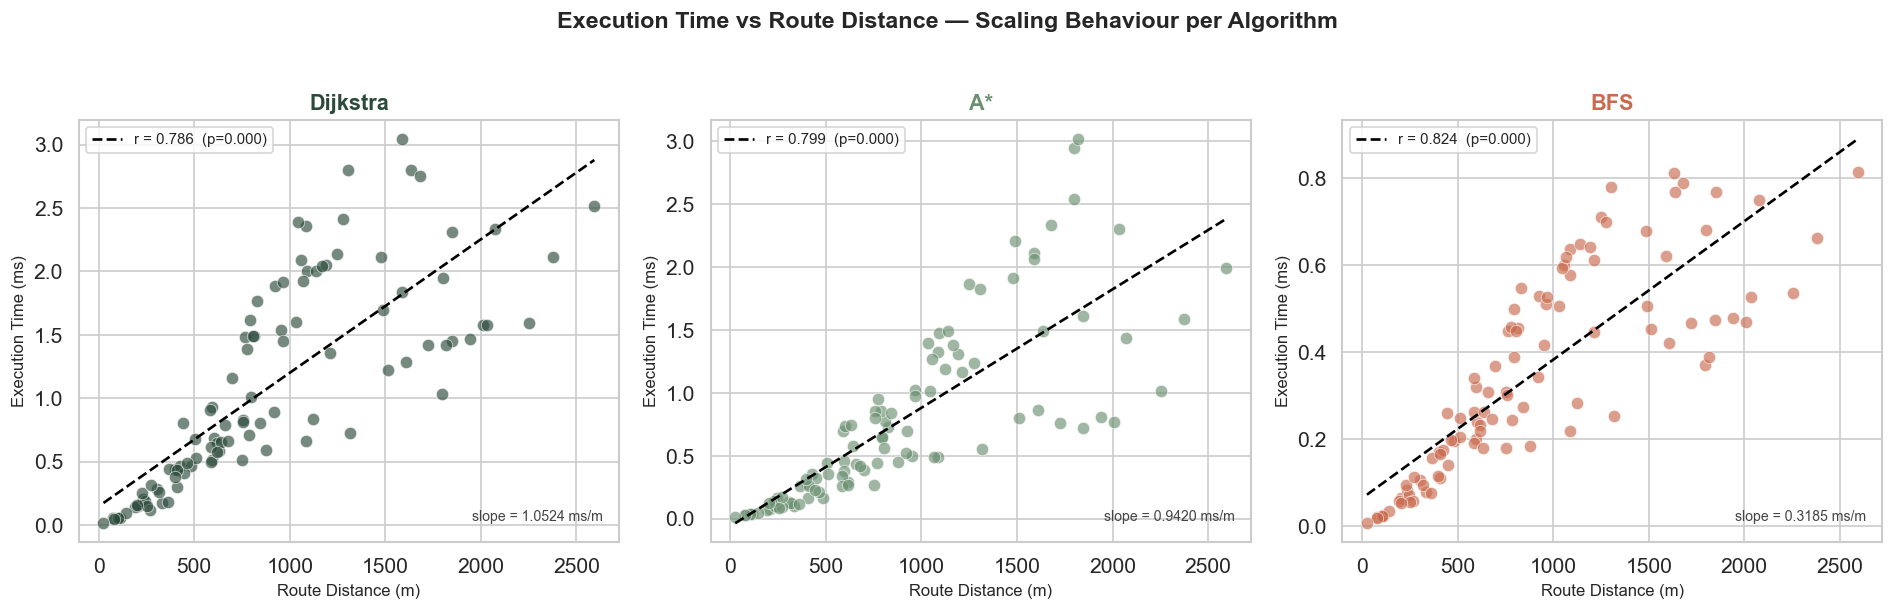

Saved → scaling_behaviour.png


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=False)
fig.suptitle('Execution Time vs Route Distance — Scaling Behaviour per Algorithm',
             fontsize=14, fontweight='bold', y=1.02)

for i, algo in enumerate(ALGO_ORDER):
    ax  = axes[i]
    sub = df[df['algorithm'] == algo].copy()

    # Scatter
    ax.scatter(sub['distance'], sub['execution_time_ms'],
               alpha=0.65, s=55, color=PALETTE[algo],
               edgecolors='white', linewidth=0.5, zorder=3)

    # Linear regression line
    m, b, r, p, se = stats.linregress(sub['distance'], sub['execution_time_ms'])
    x_line = np.linspace(sub['distance'].min(), sub['distance'].max(), 200)
    ax.plot(x_line, m * x_line + b,
            color='black', linewidth=1.6, linestyle='--',
            label=f'r = {r:.3f}  (p={p:.3f})', zorder=4)

    ax.set_title(algo, fontsize=13, fontweight='bold', color=PALETTE[algo])
    ax.set_xlabel('Route Distance (m)', fontsize=10)
    ax.set_ylabel('Execution Time (ms)', fontsize=10)
    ax.legend(fontsize=9, loc='upper left')

    # Annotate slope
    ax.text(0.97, 0.05,
            f'slope = {m*1000:.4f} ms/m',
            transform=ax.transAxes, fontsize=8.5,
            ha='right', color='#444')

plt.tight_layout()
plt.savefig('scaling_behaviour.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → scaling_behaviour.png')

---
## 9 — Per-Route Timeline: Dijkstra vs A* Head-to-Head

Each point represents one matched route. The paired display makes route-level timing differences visible. The plot is descriptive; claims about an overall timing advantage should be based on the paired differences, confidence intervals, and adjusted statistical tests reported in the paired-analysis cell.

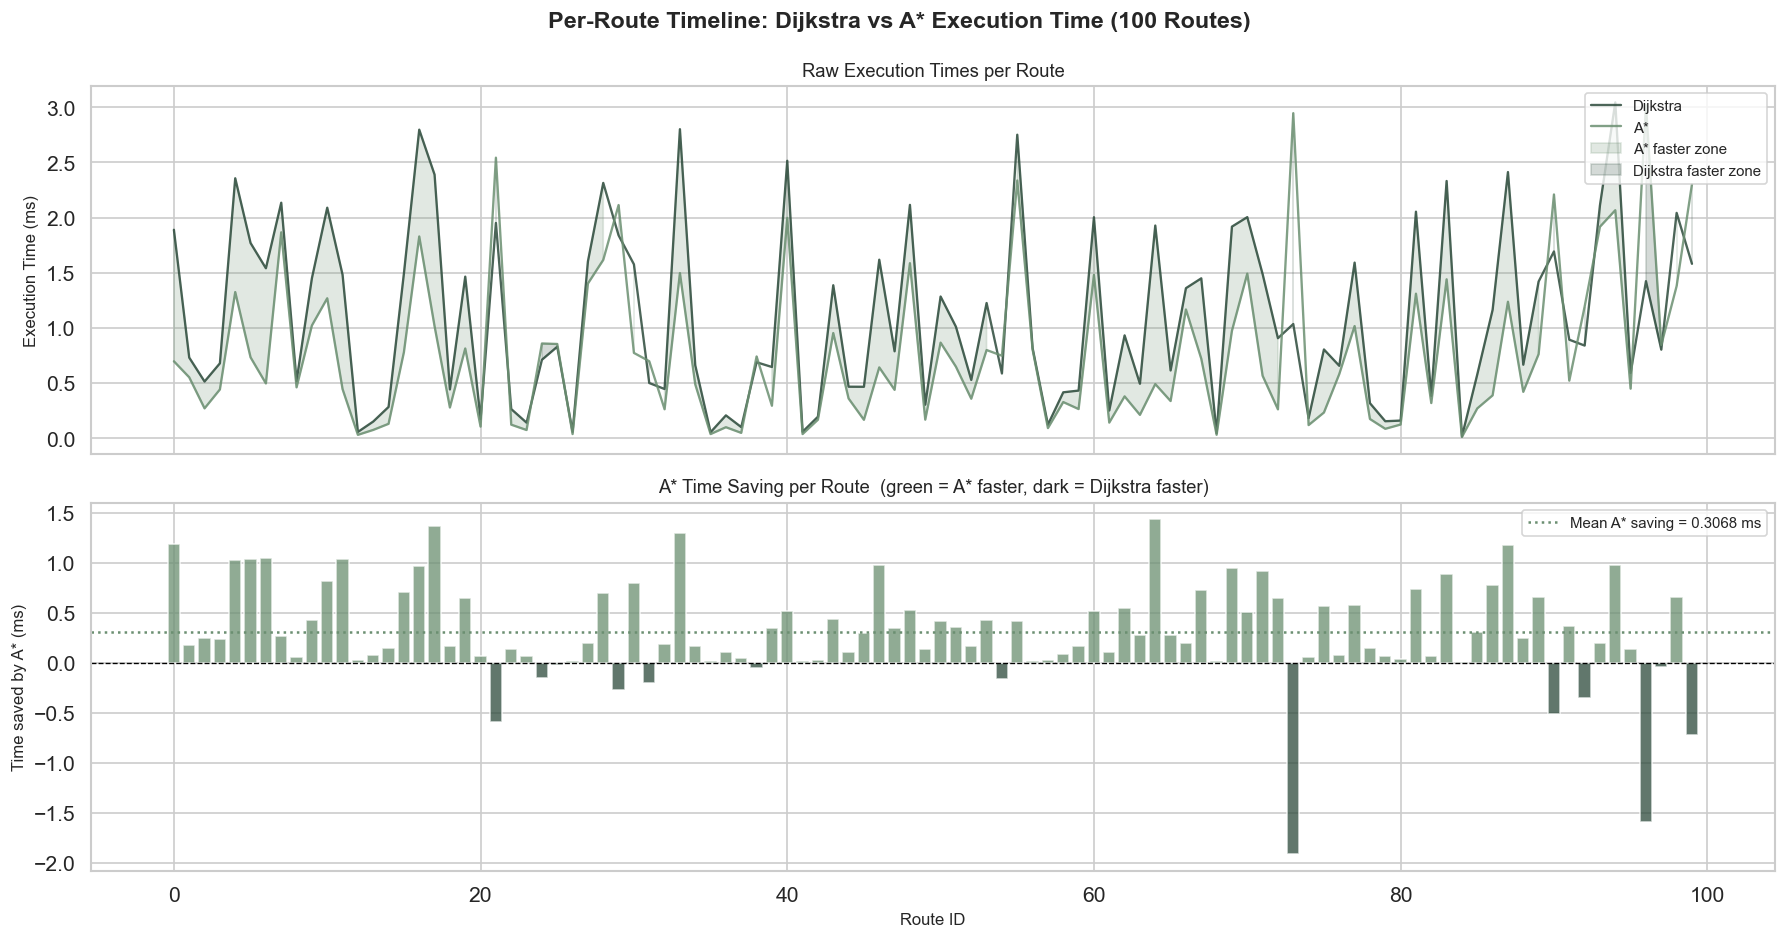

Saved → per_route_timeline.png
A* was faster on 87 / 100 routes


In [18]:
dijk_by_route  = df[df['algorithm'] == 'Dijkstra'].set_index('route_id')['execution_time_ms'].sort_index()
astar_by_route = df[df['algorithm'] == 'A*'].set_index('route_id')['execution_time_ms'].sort_index()
route_ids      = sorted(dijk_by_route.index.intersection(astar_by_route.index))

d_vals = dijk_by_route[route_ids].values
a_vals = astar_by_route[route_ids].values

fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
fig.suptitle('Per-Route Timeline: Dijkstra vs A* Execution Time (100 Routes)',
             fontsize=14, fontweight='bold')

# ── Top panel: raw time lines ─────────────────────────────────────────────────
ax1 = axes[0]
ax1.plot(route_ids, d_vals, color=PALETTE['Dijkstra'],
         alpha=0.85, linewidth=1.4, label='Dijkstra')
ax1.plot(route_ids, a_vals, color=PALETTE['A*'],
         alpha=0.85, linewidth=1.4, label='A*')
ax1.fill_between(route_ids, a_vals, d_vals,
                 where=(d_vals >= a_vals),
                 alpha=0.20, color=PALETTE['A*'],
                 label='A* faster zone')
ax1.fill_between(route_ids, a_vals, d_vals,
                 where=(d_vals < a_vals),
                 alpha=0.20, color=PALETTE['Dijkstra'],
                 label='Dijkstra faster zone')
ax1.set_ylabel('Execution Time (ms)', fontsize=10)
ax1.legend(fontsize=9, loc='upper right')
ax1.set_title('Raw Execution Times per Route', fontsize=11)

# ── Bottom panel: A* speedup delta per route ──────────────────────────────────
ax2 = axes[1]
delta = d_vals - a_vals  # positive = A* faster
colors_bar = [PALETTE['A*'] if v >= 0 else PALETTE['Dijkstra'] for v in delta]
ax2.bar(route_ids, delta, color=colors_bar, alpha=0.75, width=0.8)
ax2.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax2.axhline(np.mean(delta), color=PALETTE['A*'], linewidth=1.5,
            linestyle=':', label=f'Mean A* saving = {np.mean(delta):.4f} ms')
ax2.set_xlabel('Route ID', fontsize=10)
ax2.set_ylabel('Time saved by A* (ms)', fontsize=10)
ax2.set_title('A* Time Saving per Route  (green = A* faster, dark = Dijkstra faster)', fontsize=11)
ax2.legend(fontsize=9)

plt.tight_layout()
plt.savefig('per_route_timeline.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → per_route_timeline.png')
print(f'A* was faster on {(delta >= 0).sum()} / {len(delta)} routes')

---
## 10 — BFS Weighted-Distance Overhead

For each matched route, BFS's weighted path distance is compared with Dijkstra's distance:

$$\text{Overhead}_{\%} = \frac{d_{\text{BFS}} - d_{\text{Dijkstra}}}{d_{\text{Dijkstra}}} \times 100$$

BFS minimizes edge count rather than weighted distance. Report the full distribution of overheads and the number of routes with positive, zero, or negative overhead; do not assume every BFS route is longer. Results are specific to this graph's topology and densification.

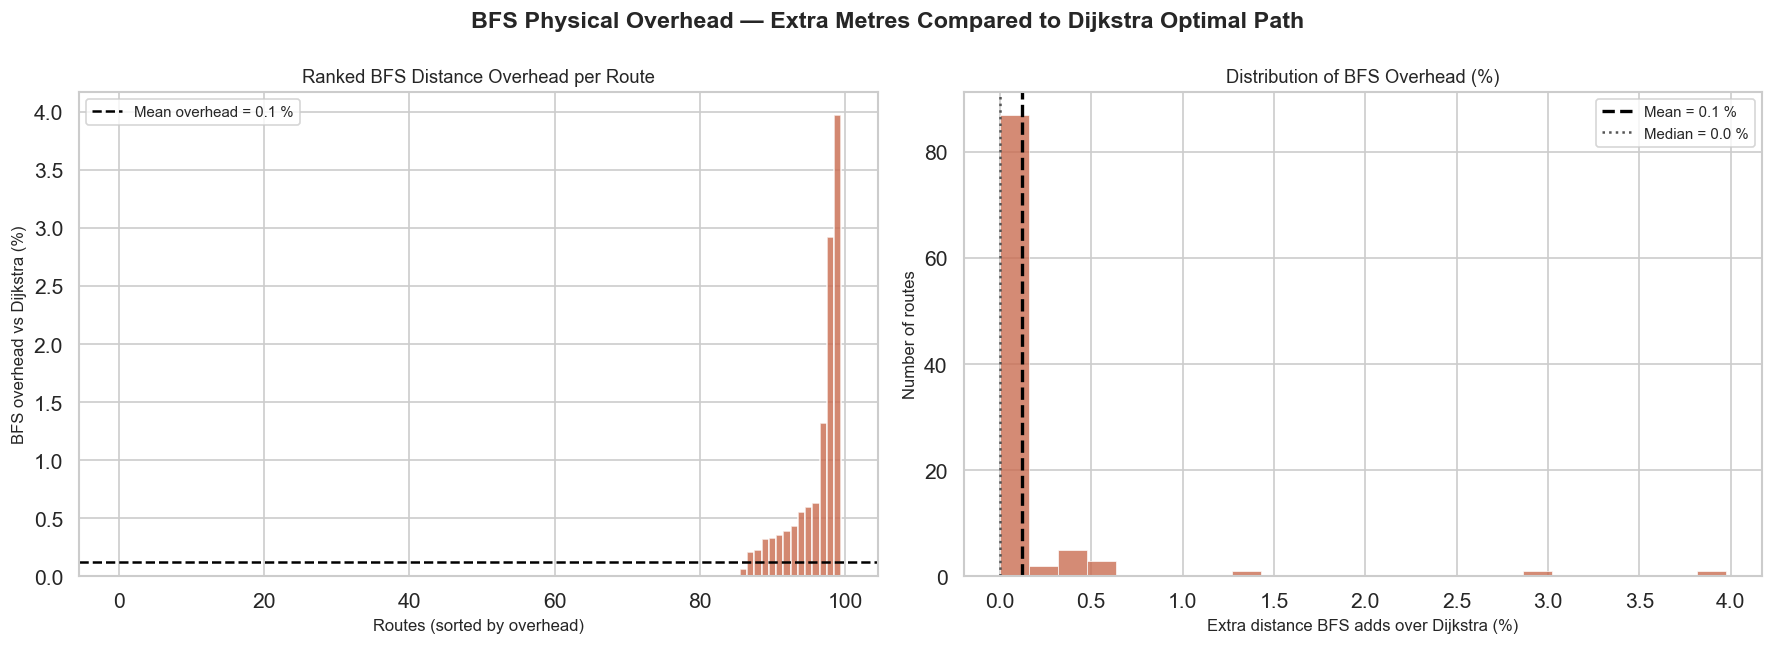

Mean BFS overhead  : +0.12 %
Median BFS overhead: +0.00 %
Max BFS overhead   : +3.97 %
Routes with 0 % overhead (BFS optimal): 86
Saved → bfs_overhead.png


In [19]:
dijk_d   = df[df['algorithm'] == 'Dijkstra'].set_index('route_id')['distance']
bfs_d    = df[df['algorithm'] == 'BFS'].set_index('route_id')['distance']
comm     = dijk_d.index.intersection(bfs_d.index)

overhead_m   = (bfs_d[comm] - dijk_d[comm])
overhead_pct = (overhead_m / dijk_d[comm] * 100)

# Sort by overhead for a ranked view
overhead_pct_sorted = overhead_pct.sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
fig.suptitle('BFS Physical Overhead — Extra Metres Compared to Dijkstra Optimal Path',
             fontsize=14, fontweight='bold')

# ── Left: per-route overhead % bar chart (sorted) ───────────────────────────
ax1 = axes[0]
bar_colors = [PALETTE['BFS'] if v > 0 else '#aaaaaa' for v in overhead_pct_sorted]
ax1.bar(range(len(overhead_pct_sorted)), overhead_pct_sorted.values,
        color=bar_colors, alpha=0.80, width=1.0)
ax1.axhline(overhead_pct_sorted.mean(), color='black', linewidth=1.5,
            linestyle='--', label=f'Mean overhead = {overhead_pct_sorted.mean():.1f} %')
ax1.axhline(0, color='gray', linewidth=0.8)
ax1.set_xlabel('Routes (sorted by overhead)', fontsize=10)
ax1.set_ylabel('BFS overhead vs Dijkstra (%)', fontsize=10)
ax1.set_title('Ranked BFS Distance Overhead per Route', fontsize=11)
ax1.legend(fontsize=9)

# ── Right: histogram of overhead % ──────────────────────────────────────────
ax2 = axes[1]
ax2.hist(overhead_pct.values, bins=25, color=PALETTE['BFS'], alpha=0.78,
         edgecolor='white', linewidth=0.5)
ax2.axvline(overhead_pct.mean(), color='black', linewidth=2,
            linestyle='--', label=f'Mean = {overhead_pct.mean():.1f} %')
ax2.axvline(overhead_pct.median(), color='#555', linewidth=1.5,
            linestyle=':', label=f'Median = {overhead_pct.median():.1f} %')
ax2.set_xlabel('Extra distance BFS adds over Dijkstra (%)', fontsize=10)
ax2.set_ylabel('Number of routes', fontsize=10)
ax2.set_title('Distribution of BFS Overhead (%)', fontsize=11)
ax2.legend(fontsize=9)

plt.tight_layout()
plt.savefig('bfs_overhead.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Mean BFS overhead  : +{overhead_pct.mean():.2f} %')
print(f'Median BFS overhead: +{overhead_pct.median():.2f} %')
print(f'Max BFS overhead   : +{overhead_pct.max():.2f} %')
print(f'Routes with 0 % overhead (BFS optimal): {(overhead_m <= 0.01).sum()}')
print('Saved → bfs_overhead.png')

---
## 11 — Node Count Distribution

This section compares the number of nodes in the paths returned by Dijkstra, A*, and BFS. BFS minimizes the number of edges, whereas Dijkstra and A* minimize total edge weight. Node count describes the returned graph path; it is not a direct measure of physical distance, computational effort, or real-world route complexity.

Because the campus graph contains intermediate points inserted during network construction, node counts may be affected by graph densification and representation choices. Interpret these distributions alongside route distance and execution time.

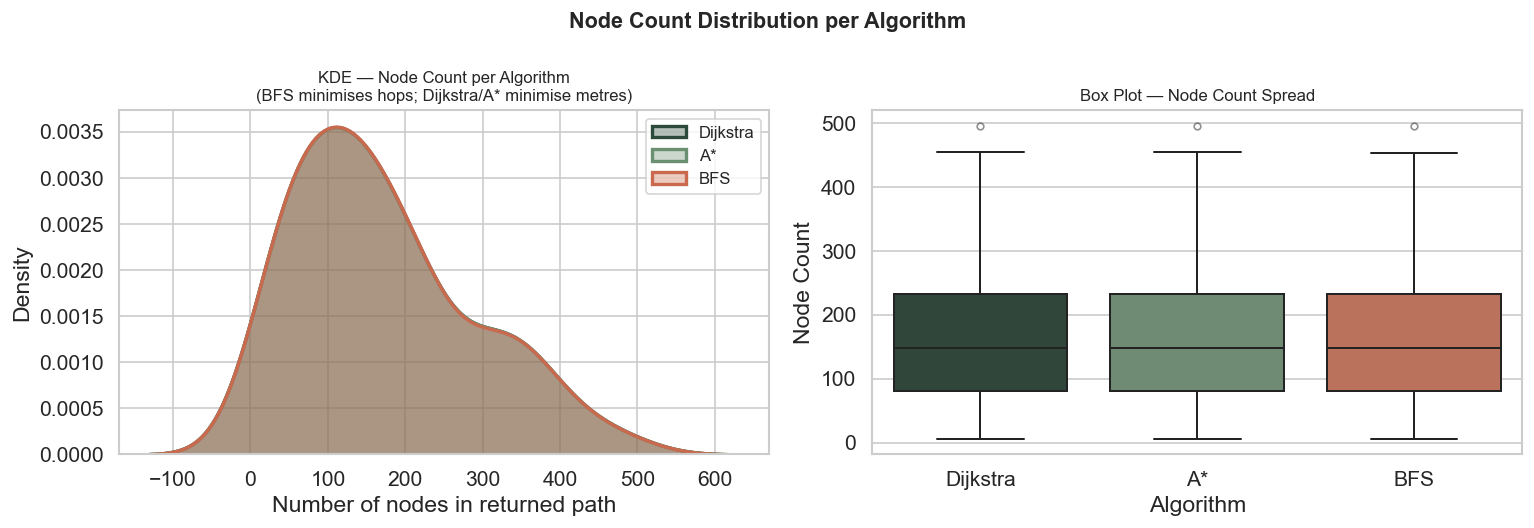

Saved → node_count_dist.png


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
fig.suptitle('Node Count Distribution per Algorithm', fontsize=13, fontweight='bold')

# ── Left: KDE ────────────────────────────────────────────────────────────────
ax1 = axes[0]
for algo in ALGO_ORDER:
    sns.kdeplot(df[df['algorithm'] == algo]['node_count'],
                ax=ax1, fill=True, alpha=0.35,
                color=PALETTE[algo], label=algo, linewidth=2)
ax1.set_xlabel('Number of nodes in returned path')
ax1.set_ylabel('Density')
ax1.set_title('KDE — Node Count per Algorithm\n(BFS minimises hops; Dijkstra/A* minimise metres)', fontsize=10)
ax1.legend(fontsize=10)

# ── Right: grouped box plot ───────────────────────────────────────────────────
ax2 = axes[1]
sns.boxplot(
    data=df, x='algorithm', y='node_count',
    palette=PALETTE, order=ALGO_ORDER,
    linewidth=1.2, flierprops=dict(marker='o', markersize=4, alpha=0.5),
    ax=ax2
)
ax2.set_xlabel('Algorithm')
ax2.set_ylabel('Node Count')
ax2.set_title('Box Plot — Node Count Spread', fontsize=10)

plt.tight_layout()
plt.savefig('node_count_dist.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → node_count_dist.png')

In [ ]:

import networkx as nx
import pandas as pd

# Store the paths returned by each algorithm for every OD pair.
results = []

for pair_id, (source, target) in enumerate(od_pairs, start=1):
    paths = {
        "Dijkstra": nx.dijkstra_path(
            G, source, target, weight="weight"
        ),
        "A*": nx.astar_path(
            G, source, target,
            heuristic=heuristic, weight="weight"
        ),
        "BFS": nx.shortest_path(
            G, source, target, weight=None
        ),
    }

    # Compare every algorithm pair.
    comparisons = [
        ("Dijkstra", "A*"),
        ("Dijkstra", "BFS"),
        ("A*", "BFS"),
    ]

    for alg1, alg2 in comparisons:
        path1 = paths[alg1]
        path2 = paths[alg2]

        edges1 = set(zip(path1[:-1], path1[1:]))
        edges2 = set(zip(path2[:-1], path2[1:]))

        # Treat edges as undirected if G is undirected.
        if not G.is_directed():
            edges1 = {frozenset(e) for e in edges1}
            edges2 = {frozenset(e) for e in edges2}

        union = edges1 | edges2
        intersection = edges1 & edges2

        overlap = (
            100 * len(intersection) / len(union)
            if union else 100.0
        )

        results.append({
            "pair_id": pair_id,
            "algorithm_1": alg1,
            "algorithm_2": alg2,
            "same_node_sequence": path1 == path2,
            "nodes_path_1": len(path1),
            "nodes_path_2": len(path2),
            "edge_jaccard_overlap_percent": overlap,
        })

comparison_df = pd.DataFrame(results)

summary = (
    comparison_df.groupby(["algorithm_1", "algorithm_2"])
    .agg(
        OD_pairs=("pair_id", "count"),
        identical_paths=("same_node_sequence", "sum"),
        mean_edge_overlap_percent=(
            "edge_jaccard_overlap_percent", "mean"
        ),
    )
    .reset_index()
)

summary["different_paths"] = (
    summary["OD_pairs"] - summary["identical_paths"]
)
summary["identical_path_percent"] = (
    100 * summary["identical_paths"] / summary["OD_pairs"]
)

print(summary.round(2).to_string(index=False))

# Save the detailed pair-by-pair results.
comparison_df.to_csv("rq3_path_comparisons.csv", index=False)


ValueError: too many values to unpack (expected 2)

---
## 12 — Summary Dashboard

A single, publication-ready **2×2 dashboard** combining the four key findings.
Designed to be included directly in the research paper as a composite figure.

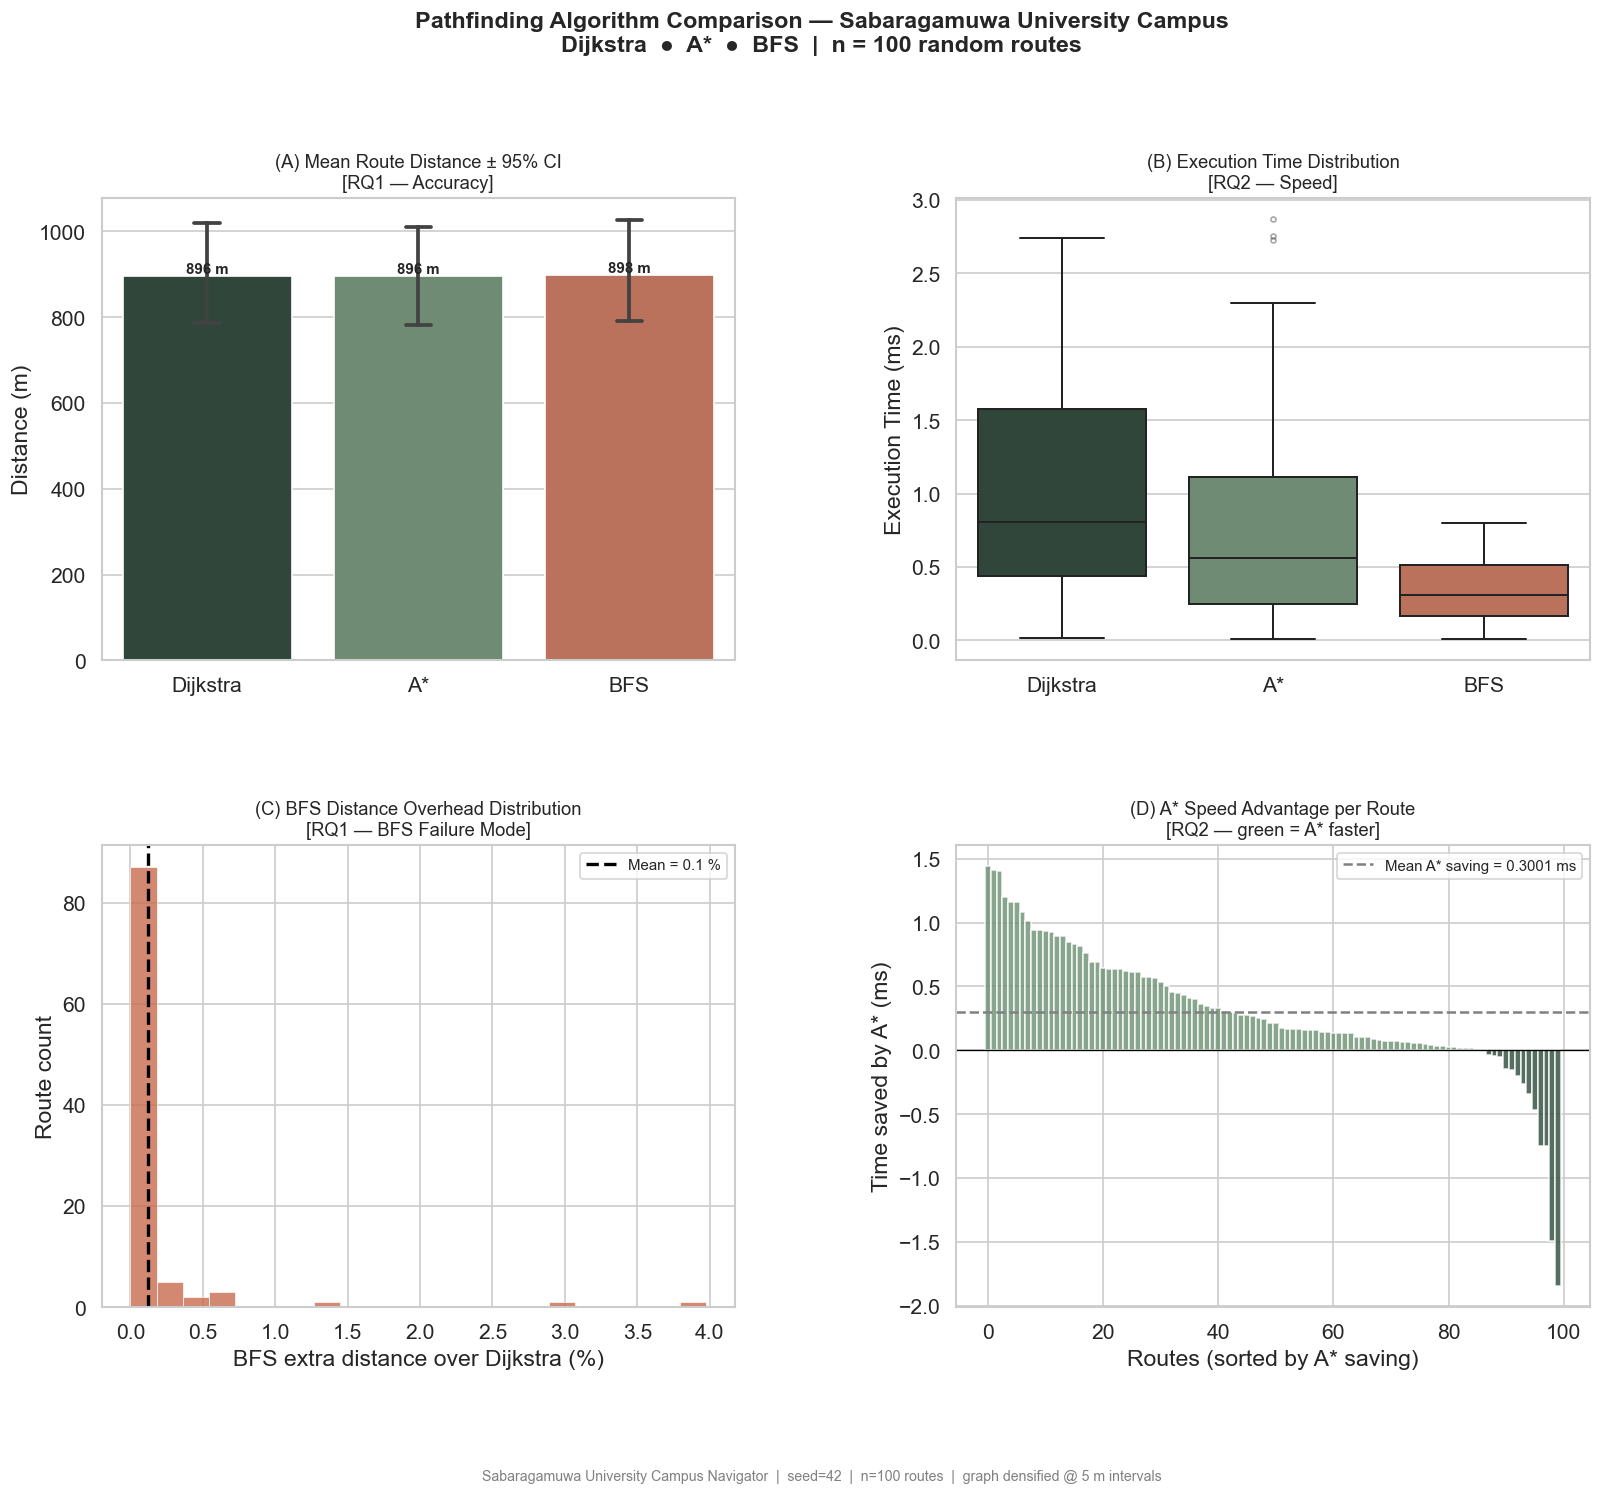

Saved → summary_dashboard.png


In [ ]:
fig = plt.figure(figsize=(16, 12))
fig.suptitle(
    'Pathfinding Algorithm Comparison — Sabaragamuwa University Campus\n'
    'Dijkstra  ●  A*  ●  BFS  |  n = 100 random routes',
    fontsize=14, fontweight='bold', y=1.01
)
gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.40, wspace=0.35)

# ══ Panel A: Mean Distance (RQ1) ═════════════════════════════════════════════
ax_a = fig.add_subplot(gs[0, 0])
sns.barplot(
    data=df, x='algorithm', y='distance',
    palette=PALETTE, errorbar=('ci', 95),
    order=ALGO_ORDER, ax=ax_a, capsize=0.12
)
for bar, algo in zip(ax_a.patches, ALGO_ORDER):
    mv = df[df['algorithm'] == algo]['distance'].mean()
    ax_a.text(bar.get_x() + bar.get_width() / 2,
              bar.get_height() + 0.5,
              f'{mv:.0f} m', ha='center', va='bottom',
              fontsize=9, fontweight='bold')
ax_a.set_title('(A) Mean Route Distance ± 95% CI\n[RQ1 — Accuracy]', fontsize=11)
ax_a.set_xlabel('')
ax_a.set_ylabel('Distance (m)')

# ══ Panel B: Execution Time Box Plot (RQ2) ═══════════════════════════════════
ax_b = fig.add_subplot(gs[0, 1])
sns.boxplot(
    data=df, x='algorithm', y='execution_time_ms',
    palette=PALETTE, order=ALGO_ORDER,
    linewidth=1.2, flierprops=dict(marker='o', markersize=3, alpha=0.4),
    ax=ax_b
)
ax_b.set_title('(B) Execution Time Distribution\n[RQ2 — Speed]', fontsize=11)
ax_b.set_xlabel('')
ax_b.set_ylabel('Execution Time (ms)')

# ══ Panel C: BFS Overhead Histogram (RQ1 detail) ═════════════════════════════
ax_c = fig.add_subplot(gs[1, 0])
ax_c.hist(overhead_pct.values, bins=22, color=PALETTE['BFS'],
          alpha=0.80, edgecolor='white', linewidth=0.5)
ax_c.axvline(overhead_pct.mean(), color='black', linewidth=2,
             linestyle='--', label=f'Mean = {overhead_pct.mean():.1f} %')
ax_c.set_xlabel('BFS extra distance over Dijkstra (%)')
ax_c.set_ylabel('Route count')
ax_c.set_title('(C) BFS Distance Overhead Distribution\n[RQ1 — BFS Failure Mode]', fontsize=11)
ax_c.legend(fontsize=9)

# ══ Panel D: A* vs Dijkstra Per-Route Time Delta ═════════════════════════════
ax_d = fig.add_subplot(gs[1, 1])
ax_d.bar(range(len(delta)), np.sort(delta)[::-1],
         color=[PALETTE['A*'] if v >= 0 else PALETTE['Dijkstra'] for v in np.sort(delta)[::-1]],
         alpha=0.80, width=1.0)
ax_d.axhline(0, color='black', linewidth=0.8)
ax_d.axhline(np.mean(delta), color='gray', linewidth=1.5, linestyle='--',
             label=f'Mean A* saving = {np.mean(delta):.4f} ms')
ax_d.set_xlabel('Routes (sorted by A* saving)')
ax_d.set_ylabel('Time saved by A* (ms)')
ax_d.set_title('(D) A* Speed Advantage per Route\n[RQ2 — green = A* faster]', fontsize=11)
ax_d.legend(fontsize=9)

# ── Footer watermark ─────────────────────────────────────────────────────────
fig.text(0.5, -0.01,
         'Sabaragamuwa University Campus Navigator  |  seed=42  |  n=100 routes  |  graph densified @ 5 m intervals',
         ha='center', fontsize=8.5, color='gray')

plt.savefig('summary_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → summary_dashboard.png')

---
## 13 — Export Results and Reproducibility

Export route-level observations, paired test tables, path-agreement summaries, and software versions. The route-level file includes the retained node sequences so that the RQ3 analysis can be reproduced.

In [ ]:
# Export route-level results and analysis tables.
df.to_csv("experiment_results.csv", index=False)
time_tests.to_csv("paired_timing_tests.csv", index=False)
distance_tests.to_csv("paired_distance_tests.csv", index=False)
path_comparison.to_csv("path_comparison_by_route.csv", index=False)
summary_path.to_csv("path_comparison_summary.csv", index=False)
component_summary.to_csv("graph_component_summary.csv", index=False)

# Final descriptive table for manuscript reporting.
final_table = (
    df.groupby("algorithm", observed=True)
      .agg(
          n_routes=("route_id", "nunique"),
          mean_time_ms=("execution_time_ms", "mean"),
          median_time_ms=("execution_time_ms", "median"),
          sd_time_ms=("execution_time_ms", "std"),
          mean_distance_m=("distance", "mean"),
          median_distance_m=("distance", "median"),
          sd_distance_m=("distance", "std"),
          mean_nodes=("node_count", "mean"),
          median_nodes=("node_count", "median"),
      )
      .round(6)
      .reset_index()
)
print("Final descriptive results table")
display(final_table)
final_table.to_csv("final_descriptive_results.csv", index=False)

# Record the software environment.
import sys
import scipy
import matplotlib

environment = pd.DataFrame([
    {"package": "Python", "version": sys.version.split()[0]},
    {"package": "NetworkX", "version": nx.__version__},
    {"package": "NumPy", "version": np.__version__},
    {"package": "pandas", "version": pd.__version__},
    {"package": "SciPy", "version": scipy.__version__},
    {"package": "Matplotlib", "version": matplotlib.__version__},
    {"package": "Seaborn", "version": sns.__version__},
])
print("Software environment")
display(environment)
environment.to_csv("software_environment.csv", index=False)

print(
    "Saved experiment_results.csv, paired_timing_tests.csv, "
    "paired_distance_tests.csv, path_comparison_by_route.csv, "
    "path_comparison_summary.csv, graph_component_summary.csv, "
    "final_descriptive_results.csv, and software_environment.csv."
)

Final descriptive results table


,algorithm,n_routes,mean_time_ms,median_time_ms,sd_time_ms,mean_distance_m,median_distance_m,sd_distance_m,mean_nodes,median_nodes
0,Dijkstra,100,1.068381,0.808812,0.789408,896.155278,780.460319,596.685224,171.40,148.5
1,A*,100,0.768237,0.560271,0.689008,896.155278,780.460319,596.685224,171.40,148.5
2,BFS,100,0.345290,0.307552,0.229171,897.658281,782.918694,597.891429,171.22,148.0


Software environment


,package,version
0,Python,3.9.6
1,NetworkX,3.2.1
2,NumPy,2.0.2
3,pandas,2.3.3
4,SciPy,1.13.1
5,Matplotlib,3.9.4
6,Seaborn,0.13.2


Saved experiment_results.csv, paired_timing_tests.csv, paired_distance_tests.csv, path_comparison_by_route.csv, path_comparison_summary.csv, graph_component_summary.csv, final_descriptive_results.csv, and software_environment.csv.


---
## 14 — Physical Route Measurements: Comparison with Application Results

This supplementary evaluation compares three named campus journeys for which two physical route distances were recorded. The application distances and execution times below are transcribed from the web application results supplied for this study; they are not generated by the random-pair experiment above.

**Interpretation note:** the two physical distances are alternative measured routes, not independently verified ground-truth shortest paths. Differences are therefore described as distance differences, not algorithm error or routing accuracy. The application reports whole-metre route distances, so its displayed precision may be lower than that of the physical measurements.


In [ ]:
# Physical measurements and application results provided for the three named journeys.
# Distances are metres; execution times are milliseconds.
physical_data = pd.DataFrame([
    {
        'journey': 'Matta Canteen → Tech Auditorium',
        'physical_path_1_m': 348.90,
        'physical_path_2_m': 771.80,
        'dijkstra_distance_m': 336.0,
        'astar_distance_m': 336.0,
        'bfs_distance_m': 336.0,
        'dijkstra_time_ms': 0.536,
        'astar_time_ms': 0.197,
        'bfs_time_ms': 0.163,
    },
    {
        'journey': 'Management Entrance → Pavilion',
        'physical_path_1_m': 401.71,
        'physical_path_2_m': 964.65,
        'dijkstra_distance_m': 423.0,
        'astar_distance_m': 423.0,
        'bfs_distance_m': 423.0,
        'dijkstra_time_ms': 0.669,
        'astar_time_ms': 0.624,
        'bfs_time_ms': 0.554,
    },
    {
        'journey': 'Social Faculty → Applied Faculty',
        'physical_path_1_m': 480.00,
        'physical_path_2_m': 667.30,
        'dijkstra_distance_m': 421.0,
        'astar_distance_m': 421.0,
        'bfs_distance_m': 421.0,
        'dijkstra_time_ms': 0.563,
        'astar_time_ms': 0.349,
        'bfs_time_ms': 0.249,
    },
])

# The three algorithms reported the same distance per journey in the application.
# Use Dijkstra's displayed distance as the common system distance for physical comparisons.
physical_data['system_distance_m'] = physical_data['dijkstra_distance_m']
physical_data['system_minus_path1_m'] = physical_data['system_distance_m'] - physical_data['physical_path_1_m']
physical_data['system_minus_path1_pct'] = 100 * physical_data['system_minus_path1_m'] / physical_data['physical_path_1_m']
physical_data['system_minus_path2_m'] = physical_data['system_distance_m'] - physical_data['physical_path_2_m']
physical_data['system_minus_path2_pct'] = 100 * physical_data['system_minus_path2_m'] / physical_data['physical_path_2_m']
physical_data['physical_path_difference_m'] = (physical_data['physical_path_2_m'] - physical_data['physical_path_1_m']).abs()

print('Physical measurements and application distances')
display(physical_data[[
    'journey', 'physical_path_1_m', 'physical_path_2_m',
    'dijkstra_distance_m', 'astar_distance_m', 'bfs_distance_m'
]].round(3))

print('Signed difference = system distance − measured path distance')
display(physical_data[[
    'journey', 'system_minus_path1_m', 'system_minus_path1_pct',
    'system_minus_path2_m', 'system_minus_path2_pct'
]].round(2))

print('Application execution times (ms) — descriptive only, n = 3 journeys')
time_summary = pd.DataFrame({
    'algorithm': ['Dijkstra', 'A*', 'BFS'],
    'mean_time_ms': [physical_data['dijkstra_time_ms'].mean(),
                     physical_data['astar_time_ms'].mean(),
                     physical_data['bfs_time_ms'].mean()],
    'median_time_ms': [physical_data['dijkstra_time_ms'].median(),
                       physical_data['astar_time_ms'].median(),
                       physical_data['bfs_time_ms'].median()],
})
display(time_summary.round(3))


Physical measurements and application distances


,journey,physical_path_1_m,physical_path_2_m,dijkstra_distance_m,astar_distance_m,bfs_distance_m
0,Matta Canteen → Tech Auditorium,348.90,771.80,336.0,336.0,336.0
1,Management Entrance → Pavilion,401.71,964.65,423.0,423.0,423.0
2,Social Faculty → Applied Faculty,480.00,667.30,421.0,421.0,421.0


Signed difference = system distance − measured path distance


,journey,system_minus_path1_m,system_minus_path1_pct,system_minus_path2_m,system_minus_path2_pct
0,Matta Canteen → Tech Auditorium,-12.90,-3.70,-435.80,-56.47
1,Management Entrance → Pavilion,21.29,5.30,-541.65,-56.15
2,Social Faculty → Applied Faculty,-59.00,-12.29,-246.30,-36.91


Application execution times (ms) — descriptive only, n = 3 journeys


,algorithm,mean_time_ms,median_time_ms
0,Dijkstra,0.589,0.563
1,A*,0.390,0.349
2,BFS,0.322,0.249


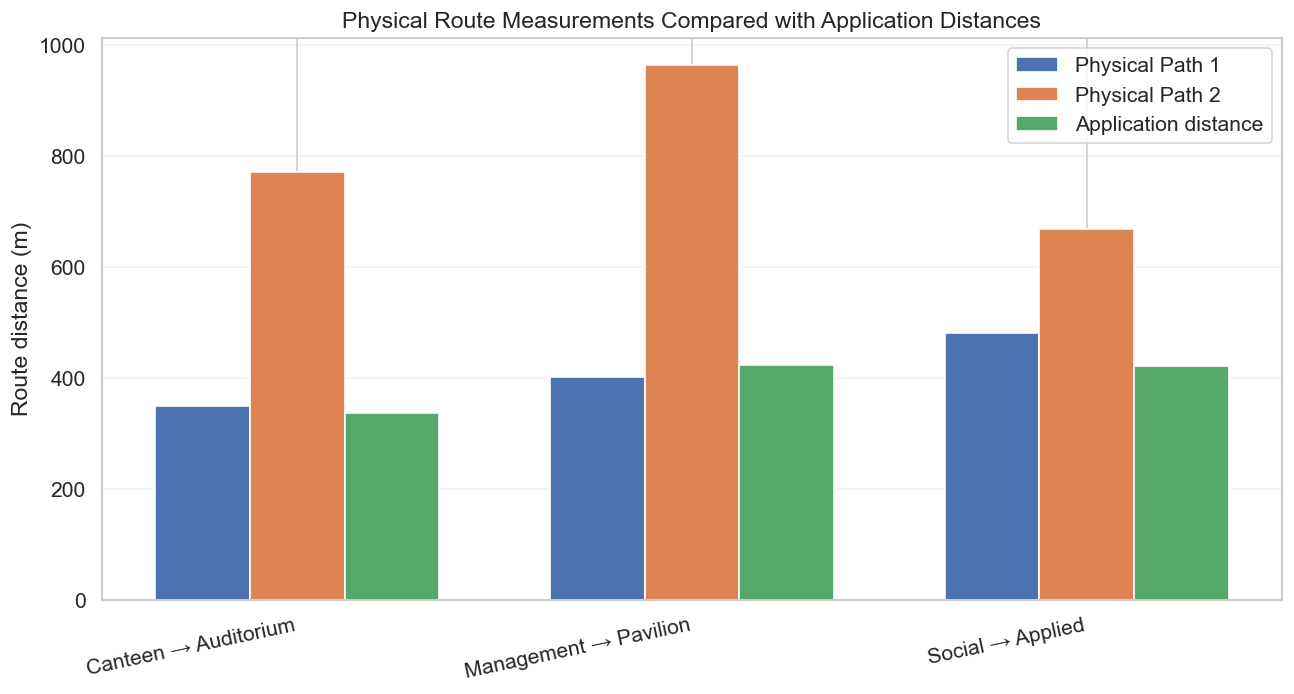

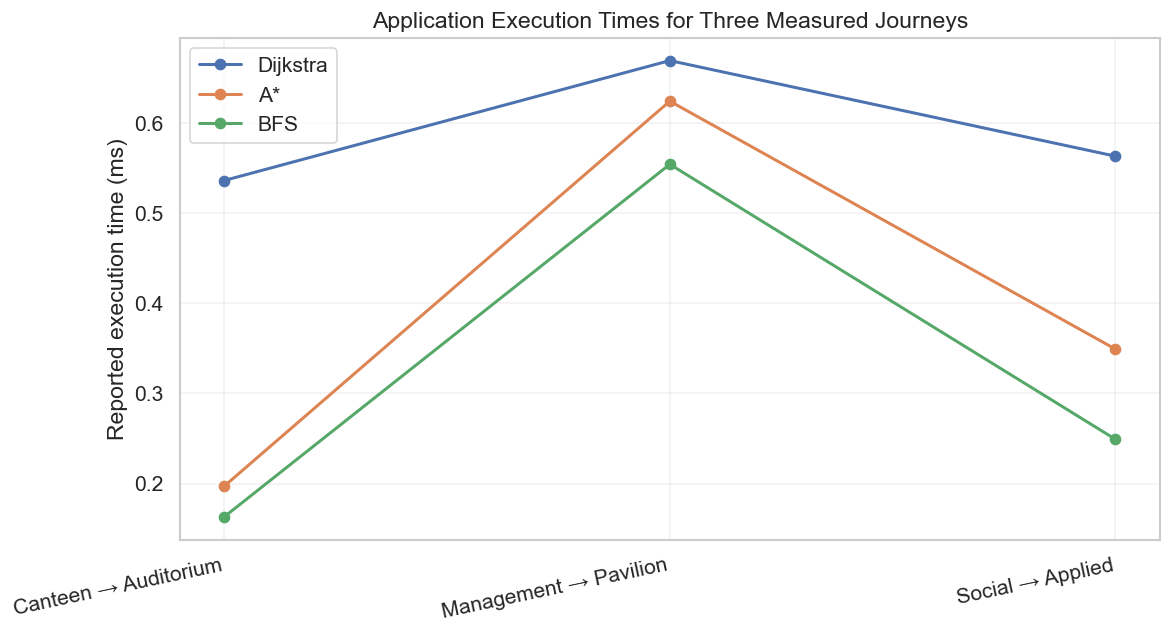

Saved: physical_route_comparison.csv
Saved: physical_route_comparison.png
Saved: physical_route_execution_times.png


In [ ]:
# Figure: measured alternatives versus the application-reported route distance.
fig, ax = plt.subplots(figsize=(11, 6))
x = np.arange(len(physical_data))
width = 0.24
ax.bar(x - width, physical_data['physical_path_1_m'], width, label='Physical Path 1')
ax.bar(x, physical_data['physical_path_2_m'], width, label='Physical Path 2')
ax.bar(x + width, physical_data['system_distance_m'], width, label='Application distance')
ax.set_ylabel('Route distance (m)')
ax.set_title('Physical Route Measurements Compared with Application Distances')
ax.set_xticks(x)
ax.set_xticklabels(['Canteen → Auditorium', 'Management → Pavilion', 'Social → Applied'], rotation=12, ha='right')
ax.legend()
ax.grid(axis='y', alpha=0.25)
fig.tight_layout()
fig.savefig('physical_route_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# Figure: application execution times for the same three journeys.
fig, ax = plt.subplots(figsize=(10, 5.5))
for col, label in [('dijkstra_time_ms', 'Dijkstra'), ('astar_time_ms', 'A*'), ('bfs_time_ms', 'BFS')]:
    ax.plot(x, physical_data[col], marker='o', linewidth=1.8, label=label)
ax.set_ylabel('Reported execution time (ms)')
ax.set_title('Application Execution Times for Three Measured Journeys')
ax.set_xticks(x)
ax.set_xticklabels(['Canteen → Auditorium', 'Management → Pavilion', 'Social → Applied'], rotation=12, ha='right')
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig('physical_route_execution_times.png', dpi=300, bbox_inches='tight')
plt.show()

physical_data.to_csv('physical_route_comparison.csv', index=False)
print('Saved: physical_route_comparison.csv')
print('Saved: physical_route_comparison.png')
print('Saved: physical_route_execution_times.png')


### Preliminary interpretation

For the three application tests supplied, all three algorithms returned the same displayed distance for each journey (336 m, 423 m, and 421 m, respectively). BFS had the lowest reported execution time in each of these three individual runs. These observations are descriptive and should not be generalized from only three journeys.

The application distance was shorter than both measured alternatives for the Canteen–Auditorium and Social–Applied Faculty journeys. For Management Entrance–Pavilion, the application distance (423 m) was 21.29 m longer than Physical Path 1 and 541.65 m shorter than Physical Path 2. These comparisons do not establish which route is truly shortest because the physical paths have not been verified as exhaustive shortest-path references and route geometry/endpoints may differ.

Before making a stronger claim, verify that the application and physical measurements use the same precise endpoints, that all compared paths are represented in the graph, and that the displayed application distances are not rounded in a way that hides differences. Also verify why BFS, which minimizes edge count rather than weighted distance, returned the same distance as Dijkstra and A* in all three examples.


---
## 15 — Conclusions and Reporting Notes

The final conclusions for RQ1–RQ3 should be written only after the notebook is rerun against the current campus graph and the generated tables/statistical tests have been checked. In particular, report the paired route-level differences between Dijkstra and A*, and use a paired comparison for execution times when the same origin–destination pairs are evaluated by each algorithm. Timing results should be interpreted cautiously because they can be affected by system load, caching, graph size, and measurement overhead.

For RQ4, the three manually supplied application tests show the same displayed route distance across all three algorithms for each journey: 336 m, 423 m, and 421 m. The reported execution times were 0.536/0.197/0.163 ms (Dijkstra/A*/BFS) for Canteen–Auditorium, 0.669/0.624/0.554 ms for Management–Pavilion, and 0.563/0.349/0.249 ms for Social–Applied Faculty. These are three descriptive observations, not a statistically robust timing benchmark.

The physical-route comparison is supplementary. The six measured distances are two alternatives for each of three journeys; they have not been established as ground-truth shortest paths. Discuss the signed distance differences and possible causes, but do not label them algorithm errors without verifying matching endpoints, comparable path geometry, map completeness, and application distance precision. Also investigate why BFS, which minimizes edge count rather than weighted distance, matches Dijkstra and A* in all three supplied examples.

**Reproducibility note:** rerun all notebook cells in order using the correct `build_graph.py` module and `SABRA.kmz-2` input before using generated tables or figures in the final paper. Keep the random seed, graph version, and software environment documented.
